In [1]:
import json
import time
import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import joblib
import sklearn

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    KFold,
    cross_validate,
    GridSearchCV,
    RandomizedSearchCV
)

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore", category=FutureWarning)

print("scikit-learn version:", sklearn.__version__)
print("Libraries imported successfully!")

scikit-learn version: 1.9.1
Libraries imported successfully!


In [ ]:
required = [
    "files",
    "preds",
    "results",
    "y_test",
    "test"
]

for name in required:
    print(f"{name}: {'Available' if name in globals() else 'Missing'}")

In [2]:
PROJECT_DIR = Path(r"D:\real-estate-price-prediction")

PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
MODELS_DIR = PROJECT_DIR / "models"
REPORTS_DIR = PROJECT_DIR / "reports"

MODEL_DATA_PATH = PROCESSED_DIR / "model_data.csv"
FEATURE_CONFIG_PATH = MODELS_DIR / "feature_config.json"

MODELS_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Modeling dataset exists:", MODEL_DATA_PATH.exists())
print("Feature configuration exists:", FEATURE_CONFIG_PATH.exists())

Project directory: D:\real-estate-price-prediction
Modeling dataset exists: True
Feature configuration exists: False


In [3]:

from pathlib import Path

PROJECT_DIR = Path(r"D:\real-estate-price-prediction")

print("Files in models folder:")
for file in sorted((PROJECT_DIR / "models").glob("*")):
    print(f"  {file.name}")

print("\nFiles in processed data folder:")
for file in sorted((PROJECT_DIR / "data" / "processed").glob("*")):
    print(f"  {file.name}")



Files in models folder:
  .gitkeep
  final_model_metadata.json
  final_price_model.joblib

Files in processed data folder:
  .gitkeep
  clean.csv
  clean_v2.csv
  clean_v3_location.csv
  clean_with_pps.csv
  distance_features.csv
  feature_engineered_v1.csv
  housing_preprocessed.csv
  location_features.csv
  model_data.csv
  test_idx.csv
  train_idx.csv


In [4]:

import pandas as pd

MODEL_DATA_PATH = PROJECT_DIR / "data" / "processed" / "model_data.csv"

data = pd.read_csv(MODEL_DATA_PATH)

print("Dataset shape:", data.shape)
print("\nColumn names:")
print(data.columns.tolist())

print("\nFirst 5 rows:")
display(data.head())

print("\nData types:")
display(data.dtypes.to_frame("Data Type"))



Dataset shape: (7457, 19)

Column names:
['prop_id', 'bedroom_num', 'bathroom_num', 'balcony_num', 'floor_num', 'total_floor', 'total_landmark_count', 'area_sqft', 'property_type', 'owntype', 'furnish', 'facing', 'age', 'locality_grouped', 'latitude', 'longitude', 'price_lakhs', 'log_price', 'split']

First 5 rows:


,prop_id,bedroom_num,bathroom_num,balcony_num,floor_num,total_floor,total_landmark_count,area_sqft,property_type,owntype,furnish,facing,age,locality_grouped,latitude,longitude,price_lakhs,log_price,split
0,O71585872,4.0,4,4.0,14.0,26.0,10.0,3434.0,Residential Apartment,1,4,1,2,Sector 84 Gurgaon,28.406534,76.962792,263.0,5.575949,test
1,T71585466,4.0,4,3.0,7.0,29.0,9.0,2870.0,Residential Apartment,1,4,1,1,Sector 81 Gurgaon,28.388907,76.951328,360.0,5.888878,train
2,I71493958,3.0,3,3.0,14.0,28.0,8.0,2802.0,Residential Apartment,1,4,0,1,Sector 112 Gurgaon,28.518677,77.015115,385.0,5.955837,train
3,X71361930,3.0,4,4.0,4.0,27.0,14.0,2290.0,Residential Apartment,1,4,2,1,Sector 104 Gurgaon,28.478440,76.986110,195.0,5.278115,train
4,N71483500,2.0,2,3.0,12.0,30.0,13.0,1400.0,Residential Apartment,1,2,3,6,Sector 74 Gurgaon,28.416400,77.012620,162.0,5.093750,train



Data types:


,Data Type
prop_id,str
bedroom_num,float64
bathroom_num,int64
balcony_num,float64
floor_num,float64
total_floor,float64
total_landmark_count,float64
area_sqft,float64
property_type,str
owntype,int64


In [5]:

import json
from pathlib import Path

PROJECT_DIR = Path(r"D:\real-estate-price-prediction")
MODELS_DIR = PROJECT_DIR / "models"
MODEL_DATA_PATH = PROJECT_DIR / "data" / "processed" / "model_data.csv"

MODELS_DIR.mkdir(parents=True, exist_ok=True)

NUM = [
    "bedroom_num",
    "bathroom_num",
    "balcony_num",
    "floor_num",
    "total_floor",
    "total_landmark_count",
    "area_sqft",
    "latitude",
    "longitude",
]

CAT = [
    "property_type",
    "owntype",
    "furnish",
    "facing",
    "age",
    "locality_grouped",
]

FEATURES = NUM + CAT

cfg = {
    "numeric_features": NUM,
    "categorical_features": CAT,
    "target": "log_price",
    "original_target": "price_lakhs",
    "identifier": "prop_id",
    "split_column": "split",
    "description": (
        "Core property features for Gurgaon real-estate price prediction. "
        "The target is log1p(price_lakhs)."
    ),
}

config_path = MODELS_DIR / "feature_config.json"

with open(config_path, "w", encoding="utf-8") as f:
    json.dump(cfg, f, indent=4)

print("Feature configuration saved to:", config_path)
print("Numeric features:", len(NUM))
print("Categorical features:", len(CAT))
print("Total features:", len(FEATURES))



Feature configuration saved to: D:\real-estate-price-prediction\models\feature_config.json
Numeric features: 9
Categorical features: 6
Total features: 15


In [6]:

import numpy as np
import pandas as pd
import json

data = pd.read_csv(MODEL_DATA_PATH)

with open(config_path, "r", encoding="utf-8") as f:
    cfg = json.load(f)

NUM = cfg["numeric_features"]
CAT = cfg["categorical_features"]
FEATURES = NUM + CAT

# Check that all features exist
missing_columns = [c for c in FEATURES if c not in data.columns]
assert not missing_columns, f"Missing features: {missing_columns}"

# Check for data leakage
banned_features = [
    c for c in FEATURES
    if c in ["prop_id", "price_lakhs", "log_price", "split"]
    or "price" in c.lower()
]

assert not banned_features, f"Potential leakage: {banned_features}"
assert not (set(NUM) & set(CAT)), "Numeric and categorical features overlap"

# Check target transformation
assert np.allclose(
    np.expm1(data["log_price"]),
    data["price_lakhs"],
    rtol=1e-5,
    atol=1e-5
), "Target transformation does not match price_lakhs"

# Verify split
print("Dataset shape:", data.shape)
print("\nSplit counts:")
print(data["split"].value_counts())

print("\nNumeric features:", len(NUM))
print("Categorical features:", len(CAT))
print("Total features:", len(FEATURES))
print("\nLeakage check: PASSED")
print("Target transformation check: PASSED")
print("Feature configuration check: PASSED")



Dataset shape: (7457, 19)

Split counts:
split
train    5965
test     1492
Name: count, dtype: int64

Numeric features: 9
Categorical features: 6
Total features: 15

Leakage check: PASSED
Target transformation check: PASSED
Feature configuration check: PASSED


In [7]:

train = data[data["split"] == "train"].copy().reset_index(drop=True)
test = data[data["split"] == "test"].copy().reset_index(drop=True)

X_train = train[FEATURES].copy()
y_train = train["log_price"].copy()

X_test = test[FEATURES].copy()
y_test = test["log_price"].copy()

print("Training features:", X_train.shape)
print("Training target:", y_train.shape)

print("Test features:", X_test.shape)
print("Test target:", y_test.shape)



Training features: (5965, 15)
Training target: (5965,)
Test features: (1492, 15)
Test target: (1492,)


In [8]:
import joblib
import numpy as np
import pandas as pd
import json
import time

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

from sklearn.model_selection import (
    KFold,
    cross_validate,
    GridSearchCV,
    RandomizedSearchCV
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("All imports completed successfully.")



All imports completed successfully.


In [9]:

def build_preprocessor(scale_numeric=False):
    """Create a preprocessing pipeline for numerical and categorical features."""

    numeric_steps = [
        ("imputer", SimpleImputer(strategy="median"))
    ]

    if scale_numeric:
        numeric_steps.append(
            ("scaler", StandardScaler())
        )

    numeric_pipeline = Pipeline(numeric_steps)

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])

    preprocessor = ColumnTransformer([
        ("numeric", numeric_pipeline, NUM),
        ("categorical", categorical_pipeline, CAT)
    ])

    return preprocessor


# Separate preprocessors
linear_preprocessor = build_preprocessor(scale_numeric=True)
tree_preprocessor = build_preprocessor(scale_numeric=False)

print("Linear Regression preprocessor created.")
print("Tree-model preprocessor created.")



Linear Regression preprocessor created.
Tree-model preprocessor created.


In [10]:

print("Missing values in training features:")
missing_counts = X_train.isna().sum()
display(missing_counts[missing_counts > 0])

if missing_counts.sum() == 0:
    print("No missing feature values found.")

print("\nTarget missing values:", y_train.isna().sum())
print("Infinite target values:", np.isinf(y_train).sum())

assert y_train.notna().all(), "Target contains missing values."
assert np.isfinite(y_train).all(), "Target contains infinite values."

print("\nTraining-data checks passed.")



Missing values in training features:


balcony_num      3
floor_num      602
total_floor      1
dtype: int64


Target missing values: 0
Infinite target values: 0

Training-data checks passed.


In [11]:
models = {
    "Linear Regression": Pipeline([
        ("preprocessor", build_preprocessor(scale_numeric=True)),
        ("model", LinearRegression())
    ]),

    "Decision Tree": Pipeline([
        ("preprocessor", build_preprocessor(scale_numeric=False)),
        ("model", DecisionTreeRegressor(random_state=42))
    ]),

    "Random Forest": Pipeline([
        ("preprocessor", build_preprocessor(scale_numeric=False)),
        ("model", RandomForestRegressor(
            n_estimators=200,
            random_state=42,
            n_jobs=-1
        ))
    ]),

    "Gradient Boosting": Pipeline([
        ("preprocessor", build_preprocessor(scale_numeric=False)),
        ("model", GradientBoostingRegressor(random_state=42))
    ])
}

print("Models created:")
for name in models:
    print("-", name)



Models created:
- Linear Regression
- Decision Tree
- Random Forest
- Gradient Boosting


In [12]:

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Cross-validation strategy created.")
print("Number of folds:", cv.get_n_splits())
print("Training samples:", len(X_train))



Cross-validation strategy created.
Number of folds: 5
Training samples: 5965


In [13]:

baseline = DummyRegressor(strategy="mean")

baseline_scores = cross_validate(
    baseline,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "r2": "r2",
        "mae": "neg_mean_absolute_error",
        "rmse": "neg_root_mean_squared_error"
    },
    n_jobs=-1,
    return_train_score=False
)

baseline_results = {
    "Model": "Dummy Baseline",
    "CV R2": baseline_scores["test_r2"].mean(),
    "CV MAE (log)": -baseline_scores["test_mae"].mean(),
    "CV RMSE (log)": -baseline_scores["test_rmse"].mean()
}

print(pd.Series(baseline_results))



Model            Dummy Baseline
CV R2                 -0.000892
CV MAE (log)           0.492475
CV RMSE (log)           0.61309
dtype: object


In [14]:

initial_results = []

for name, model in models.items():
    print(f"\nEvaluating {name}...")

    start_time = time.time()

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "r2": "r2",
            "mae": "neg_mean_absolute_error",
            "rmse": "neg_root_mean_squared_error"
        },
        n_jobs=1,
        return_train_score=False
    )

    elapsed = time.time() - start_time

    result = {
        "Model": name,
        "CV R2": scores["test_r2"].mean(),
        "CV MAE (log)": -scores["test_mae"].mean(),
        "CV RMSE (log)": -scores["test_rmse"].mean(),
        "Time (seconds)": round(elapsed, 2)
    }

    initial_results.append(result)

    print(f"CV R2: {result['CV R2']:.4f}")
    print(f"CV MAE (log): {result['CV MAE (log)']:.4f}")
    print(f"CV RMSE (log): {result['CV RMSE (log)']:.4f}")
    print(f"Time: {elapsed:.2f} seconds")

initial_results_df = pd.DataFrame(initial_results)

display(
    initial_results_df.sort_values(
        by="CV MAE (log)",
        ascending=True
    ).reset_index(drop=True)
)




Evaluating Linear Regression...
CV R2: 0.8531
CV MAE (log): 0.1723
CV RMSE (log): 0.2345
Time: 0.50 seconds

Evaluating Decision Tree...
CV R2: 0.8279
CV MAE (log): 0.1623
CV RMSE (log): 0.2538
Time: 1.52 seconds

Evaluating Random Forest...
CV R2: 0.9066
CV MAE (log): 0.1241
CV RMSE (log): 0.1869
Time: 57.46 seconds

Evaluating Gradient Boosting...
CV R2: 0.8779
CV MAE (log): 0.1588
CV RMSE (log): 0.2135
Time: 7.28 seconds


,Model,CV R2,CV MAE (log),CV RMSE (log),Time (seconds)
0,Random Forest,0.906584,0.124084,0.186871,57.46
1,Gradient Boosting,0.877936,0.158771,0.213511,7.28
2,Decision Tree,0.827928,0.162298,0.253811,1.52
3,Linear Regression,0.853135,0.172281,0.234517,0.50


In [15]:

# Hyperparameter search spaces

param_grids = {
    "Linear Regression": {
        "model__fit_intercept": [True, False],
        "model__positive": [False, True]
    },

    "Decision Tree": {
        "model__max_depth": [None, 8, 12, 16, 20, 30],
        "model__min_samples_split": [2, 5, 10, 20],
        "model__min_samples_leaf": [1, 2, 4, 8],
        "model__max_features": [None, 0.8, 1.0]
    },

    "Random Forest": {
        "model__n_estimators": [200, 300, 400, 500],
        "model__max_depth": [None, 15, 20, 25, 30],
        "model__min_samples_split": [2, 5, 10],
        "model__min_samples_leaf": [1, 2, 4],
        "model__max_features": [0.7, 0.85, 1.0]
    },

    "Gradient Boosting": {
        "model__n_estimators": [100, 200, 300, 400],
        "model__learning_rate": [0.03, 0.05, 0.08, 0.1],
        "model__max_depth": [2, 3, 4],
        "model__min_samples_split": [2, 5, 10],
        "model__min_samples_leaf": [1, 2, 4],
        "model__subsample": [0.8, 0.9, 1.0]
    }
}

for name, grid in param_grids.items():
    print(f"{name}: {len(grid)} hyperparameters/settings groups")



Linear Regression: 2 hyperparameters/settings groups
Decision Tree: 4 hyperparameters/settings groups
Random Forest: 5 hyperparameters/settings groups
Gradient Boosting: 6 hyperparameters/settings groups


In [16]:
searches = {
    "Linear Regression": GridSearchCV(
        estimator=models["Linear Regression"],
        param_grid=param_grids["Linear Regression"],
        scoring="neg_mean_absolute_error",
        cv=cv,
        n_jobs=-1,
        refit=True,
        return_train_score=True
    ),

    "Decision Tree": RandomizedSearchCV(
        estimator=models["Decision Tree"],
        param_distributions=param_grids["Decision Tree"],
        n_iter=30,
        scoring="neg_mean_absolute_error",
        cv=cv,
        random_state=42,
        n_jobs=-1,
        refit=True,
        return_train_score=True
    ),

    "Random Forest": RandomizedSearchCV(
        estimator=models["Random Forest"],
        param_distributions=param_grids["Random Forest"],
        n_iter=20,
        scoring="neg_mean_absolute_error",
        cv=cv,
        random_state=42,
        n_jobs=1,
        refit=True,
        return_train_score=True
    ),

    "Gradient Boosting": RandomizedSearchCV(
        estimator=models["Gradient Boosting"],
        param_distributions=param_grids["Gradient Boosting"],
        n_iter=20,
        scoring="neg_mean_absolute_error",
        cv=cv,
        random_state=42,
        n_jobs=-1,
        refit=True,
        return_train_score=True
    )
}

print("Search objects created for all four models.")



Search objects created for all four models.


In [18]:

tuning_results = []
best_pipelines = {}
best_params = {}

for name, search in searches.items():
    print(f"\n{'=' * 60}")
    print(f"Tuning: {name}")
    print(f"{'=' * 60}")

    start_time = time.time()

    search.fit(X_train, y_train)

    elapsed = time.time() - start_time

    best_pipelines[name] = search.best_estimator_
    best_params[name] = search.best_params_
    
    result = {
        "Model": name,
        "Best CV MAE (log)": -search.best_score_,
        "Tuning Time (seconds)": round(elapsed, 2),
        "Best Parameters": search.best_params_
    }
    tuning_results.append(result)

    print(f"Best CV MAE (log): {-search.best_score_:.5f}")
    print(f"Time: {elapsed:.2f} seconds")
    print("Best parameters:")
    print(search.best_params_)

tuning_results_df = pd.DataFrame(tuning_results)

display(
    tuning_results_df[
        ["Model", "Best CV MAE (log)", "Tuning Time (seconds)"]
    ].sort_values("Best CV MAE (log)")
)




Tuning: Linear Regression


d:\real-estate-price-prediction\venv\Lib\site-packages\sklearn\model_selection\_validation.py:493: FitFailedWarning: 
10 fits failed out of a total of 20.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
10 fits failed with the following error:
Traceback (most recent call last):
  File "d:\real-estate-price-prediction\venv\Lib\site-packages\sklearn\model_selection\_validation.py", line 855, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "d:\real-estate-price-prediction\venv\Lib\site-packages\sklearn\base.py", line 1403, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "d:\real-estate-price-prediction\venv\Lib\site-packages\sklearn\pipeline.py"

Best CV MAE (log): 0.17228
Time: 0.71 seconds
Best parameters:
{'model__fit_intercept': True, 'model__positive': False}

Tuning: Decision Tree
Best CV MAE (log): 0.15679
Time: 6.21 seconds
Best parameters:
{'model__min_samples_split': 20, 'model__min_samples_leaf': 1, 'model__max_features': None, 'model__max_depth': 20}

Tuning: Random Forest


KeyboardInterrupt: 

In [19]:

import time
import json
import joblib
import pandas as pd
import numpy as np

from pathlib import Path
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV

# --------------------------------------------------
# 1. Set output directories
# --------------------------------------------------
PROJECT_DIR = Path(r"D:\real-estate-price-prediction")
MODELS_DIR = PROJECT_DIR / "models"
REPORTS_DIR = PROJECT_DIR / "reports"

MODELS_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

# --------------------------------------------------
# 2. Define the four model pipelines
# --------------------------------------------------
models = {
    "Linear Regression": Pipeline([
        ("preprocessor", build_preprocessor(scale_numeric=True)),
        ("model", LinearRegression())
    ]),

    "Decision Tree": Pipeline([
        ("preprocessor", build_preprocessor(scale_numeric=False)),
        ("model", DecisionTreeRegressor(random_state=42))
    ]),

    "Random Forest": Pipeline([
        ("preprocessor", build_preprocessor(scale_numeric=False)),
        ("model", RandomForestRegressor(
            random_state=42,
            n_jobs=-1
        ))
    ]),

    "Gradient Boosting": Pipeline([
        ("preprocessor", build_preprocessor(scale_numeric=False)),
        ("model", GradientBoostingRegressor(random_state=42))
    ])
}

# --------------------------------------------------
# 3. Define hyperparameter search spaces
# --------------------------------------------------
param_grids = {
    "Linear Regression": {
        "model__fit_intercept": [True, False],
        "model__positive": [False, True]
    },

    "Decision Tree": {
        "model__max_depth": [None, 8, 12, 16, 20, 30],
        "model__min_samples_split": [2, 5, 10, 20],
        "model__min_samples_leaf": [1, 2, 4, 8],
        "model__max_features": [None, 0.8, 1.0]
    },

    "Random Forest": {
        "model__n_estimators": [200, 300, 400, 500],
        "model__max_depth": [None, 15, 20, 25, 30],
        "model__min_samples_split": [2, 5, 10],
        "model__min_samples_leaf": [1, 2, 4],
        "model__max_features": [0.7, 0.85, 1.0]
    },

    "Gradient Boosting": {
        "model__n_estimators": [100, 200, 300, 400],
        "model__learning_rate": [0.03, 0.05, 0.08, 0.1],
        "model__max_depth": [2, 3, 4],
        "model__min_samples_split": [2, 5, 10],
        "model__min_samples_leaf": [1, 2, 4],
        "model__subsample": [0.8, 0.9, 1.0]
    }
}

# --------------------------------------------------
# 4. Configure searches
# --------------------------------------------------
searches = {
    "Linear Regression": GridSearchCV(
        models["Linear Regression"],
        param_grids["Linear Regression"],
        scoring="neg_mean_absolute_error",
        cv=cv,
        n_jobs=-1,
        refit=True,
        return_train_score=True
    ),

    "Decision Tree": RandomizedSearchCV(
        models["Decision Tree"],
        param_grids["Decision Tree"],
        n_iter=30,
        scoring="neg_mean_absolute_error",
        cv=cv,
        random_state=42,
        n_jobs=-1,
        refit=True,
        return_train_score=True
    ),

    "Random Forest": RandomizedSearchCV(
        models["Random Forest"],
        param_grids["Random Forest"],
        n_iter=20,
        scoring="neg_mean_absolute_error",
        cv=cv,
        random_state=42,
        n_jobs=1,
        refit=True,
        return_train_score=True
    ),

    "Gradient Boosting": RandomizedSearchCV(
        models["Gradient Boosting"],
        param_grids["Gradient Boosting"],
        n_iter=20,
        scoring="neg_mean_absolute_error",
        cv=cv,
        random_state=42,
        n_jobs=-1,
        refit=True,
        return_train_score=True
    )
}

# --------------------------------------------------
# 5. Tune all models using training data only
# --------------------------------------------------
tuning_results = []
best_pipelines = {}
best_params = {}

for name, search in searches.items():
    print("\n" + "=" * 65)
    print(f"TUNING: {name}")
    print("=" * 65)

    start_time = time.time()

    search.fit(X_train, y_train)

    elapsed = time.time() - start_time

    best_pipelines[name] = search.best_estimator_
    best_params[name] = search.best_params_

    result = {
        "Model": name,
        "Best CV MAE (log)": -search.best_score_,
        "Tuning Time (seconds)": round(elapsed, 2),
        "Best Parameters": json.dumps(search.best_params_)
    }

    tuning_results.append(result)

    print(f"Best CV MAE (log): {-search.best_score_:.5f}")
    print(f"Tuning time: {elapsed:.2f} seconds")
    print("Best parameters:", search.best_params_)

# --------------------------------------------------
# 6. Create and display comparison table
# --------------------------------------------------
tuning_results_df = pd.DataFrame(tuning_results)

tuning_results_df = tuning_results_df.sort_values(
    "Best CV MAE (log)",
    ascending=True
).reset_index(drop=True)

print("\nFINAL TUNING COMPARISON")
display(tuning_results_df)

# --------------------------------------------------
# 7. Save tuned pipelines
# --------------------------------------------------
for name, pipeline in best_pipelines.items():
    filename = name.lower().replace(" ", "_") + "_tuned.joblib"
    output_path = MODELS_DIR / filename

    joblib.dump(pipeline, output_path)
    print("Saved pipeline:", output_path)

# --------------------------------------------------
# 8. Save best parameters
# --------------------------------------------------
params_path = MODELS_DIR / "best_model_params.json"

with open(params_path, "w", encoding="utf-8") as f:
    json.dump(best_params, f, indent=4, default=str)

print("\nSaved best parameters:", params_path)

# --------------------------------------------------
# 9. Save tuning results
# --------------------------------------------------
results_path = REPORTS_DIR / "model_tuning_results.csv"

tuning_results_df.to_csv(results_path, index=False)

print("Saved comparison table:", results_path)

print("\n" + "=" * 65)
print("HYPERPARAMETER TUNING COMPLETED SUCCESSFULLY")
print("=" * 65)
print("Models tuned:", len(best_pipelines))
print("Cross-validation folds:", cv.get_n_splits())
print("Training samples:", len(X_train))
print("Test data was not used during tuning.")




TUNING: Linear Regression


d:\real-estate-price-prediction\venv\Lib\site-packages\sklearn\model_selection\_validation.py:493: FitFailedWarning: 
10 fits failed out of a total of 20.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
10 fits failed with the following error:
Traceback (most recent call last):
  File "d:\real-estate-price-prediction\venv\Lib\site-packages\sklearn\model_selection\_validation.py", line 855, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "d:\real-estate-price-prediction\venv\Lib\site-packages\sklearn\base.py", line 1403, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "d:\real-estate-price-prediction\venv\Lib\site-packages\sklearn\pipeline.py"

Best CV MAE (log): 0.17228
Tuning time: 19.04 seconds
Best parameters: {'model__fit_intercept': True, 'model__positive': False}

TUNING: Decision Tree
Best CV MAE (log): 0.15679
Tuning time: 9.54 seconds
Best parameters: {'model__min_samples_split': 20, 'model__min_samples_leaf': 1, 'model__max_features': None, 'model__max_depth': 20}

TUNING: Random Forest
Best CV MAE (log): 0.12237
Tuning time: 967.67 seconds
Best parameters: {'model__n_estimators': 400, 'model__min_samples_split': 5, 'model__min_samples_leaf': 1, 'model__max_features': 0.7, 'model__max_depth': None}

TUNING: Gradient Boosting
Best CV MAE (log): 0.13269
Tuning time: 60.79 seconds
Best parameters: {'model__subsample': 0.9, 'model__n_estimators': 400, 'model__min_samples_split': 5, 'model__min_samples_leaf': 2, 'model__max_depth': 4, 'model__learning_rate': 0.05}

FINAL TUNING COMPARISON


,Model,Best CV MAE (log),Tuning Time (seconds),Best Parameters
0,Random Forest,0.122373,967.67,"{""model__n_estimators"": 400, ""model__min_sampl..."
1,Gradient Boosting,0.132688,60.79,"{""model__subsample"": 0.9, ""model__n_estimators..."
2,Decision Tree,0.156793,9.54,"{""model__min_samples_split"": 20, ""model__min_s..."
3,Linear Regression,0.172281,19.04,"{""model__fit_intercept"": true, ""model__positiv..."


Saved pipeline: D:\real-estate-price-prediction\models\linear_regression_tuned.joblib
Saved pipeline: D:\real-estate-price-prediction\models\decision_tree_tuned.joblib
Saved pipeline: D:\real-estate-price-prediction\models\random_forest_tuned.joblib
Saved pipeline: D:\real-estate-price-prediction\models\gradient_boosting_tuned.joblib

Saved best parameters: D:\real-estate-price-prediction\models\best_model_params.json
Saved comparison table: D:\real-estate-price-prediction\reports\model_tuning_results.csv

HYPERPARAMETER TUNING COMPLETED SUCCESSFULLY
Models tuned: 4
Cross-validation folds: 5
Training samples: 5965
Test data was not used during tuning.


In [20]:

import json
import joblib
import numpy as np
import pandas as pd

from pathlib import Path
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

# --------------------------------------------------
# 1. Project paths
# --------------------------------------------------
PROJECT_DIR = Path(r"D:\real-estate-price-prediction")
MODELS_DIR = PROJECT_DIR / "models"
REPORTS_DIR = PROJECT_DIR / "reports"

# --------------------------------------------------
# 2. Load test data
# --------------------------------------------------
data = pd.read_csv(
    PROJECT_DIR / "data" / "processed" / "model_data.csv"
)

test = data[data["split"] == "test"].copy().reset_index(drop=True)

with open(
    MODELS_DIR / "feature_config.json",
    "r",
    encoding="utf-8"
) as f:
    cfg = json.load(f)

NUM = cfg["numeric_features"]
CAT = cfg["categorical_features"]
FEATURES = NUM + CAT

X_test = test[FEATURES].copy()
y_test_log = test["log_price"].to_numpy()
y_test_price = test["price_lakhs"].to_numpy()

print("Test samples:", len(test))

# --------------------------------------------------
# 3. Load each tuned pipeline and evaluate
# --------------------------------------------------
model_files = {
    "Linear Regression": "linear_regression_tuned.joblib",
    "Decision Tree": "decision_tree_tuned.joblib",
    "Random Forest": "random_forest_tuned.joblib",
    "Gradient Boosting": "gradient_boosting_tuned.joblib"
}

results = []
predictions = {}

for name, filename in model_files.items():
    model_path = MODELS_DIR / filename
    model = joblib.load(model_path)

    # Predict log-price
    pred_log = model.predict(X_test)

    # Convert predictions to original price scale
    pred_price = np.expm1(pred_log)

    # Store predictions
    predictions[name] = pred_price

    # Metrics on log scale
    log_r2 = r2_score(y_test_log, pred_log)
    log_mae = mean_absolute_error(y_test_log, pred_log)
    log_rmse = np.sqrt(mean_squared_error(y_test_log, pred_log))

    # Metrics on original price scale
    price_r2 = r2_score(y_test_price, pred_price)
    price_mae = mean_absolute_error(y_test_price, pred_price)
    price_rmse = np.sqrt(mean_squared_error(y_test_price, pred_price))

    results.append({
        "Model": name,
        "Test R2 (log)": log_r2,
        "Test MAE (log)": log_mae,
        "Test RMSE (log)": log_rmse,
        "Test R2 (price)": price_r2,
        "Test MAE (lakhs)": price_mae,
        "Test RMSE (lakhs)": price_rmse
    })

# --------------------------------------------------
# 4. Display results
# --------------------------------------------------
results_df = pd.DataFrame(results).sort_values(
    "Test MAE (lakhs)",
    ascending=True
).reset_index(drop=True)

display(results_df.round(4))

# --------------------------------------------------
# 5. Save results
# --------------------------------------------------
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

results_path = REPORTS_DIR / "test_evaluation_results.csv"
results_df.to_csv(results_path, index=False)

print("\nTest evaluation results saved to:")
print(results_path)

print("\nBest model by test MAE:")
print(results_df.iloc[0]["Model"])

print(
    "Test MAE:",
    round(results_df.iloc[0]["Test MAE (lakhs)"], 2),
    "lakhs"
)



Test samples: 1492


,Model,Test R2 (log),Test MAE (log),Test RMSE (log),Test R2 (price),Test MAE (lakhs),Test RMSE (lakhs)
0,Random Forest,0.9175,0.1169,0.1772,0.9010,43.3703,100.8134
1,Gradient Boosting,0.9079,0.1341,0.1873,0.8949,49.7949,103.8771
2,Decision Tree,0.8516,0.1561,0.2376,0.8727,56.0719,114.3299
3,Linear Regression,0.8607,0.1710,0.2303,0.7882,67.8057,147.4914



Test evaluation results saved to:
D:\real-estate-price-prediction\reports\test_evaluation_results.csv

Best model by test MAE:
Random Forest
Test MAE: 43.37 lakhs


In [21]:

from pathlib import Path
import joblib
import json
import numpy as np
import pandas as pd

PROJECT_DIR = Path(r"D:\real-estate-price-prediction")
MODELS_DIR = PROJECT_DIR / "models"
REPORTS_DIR = PROJECT_DIR / "reports"

MODEL_PATH = MODELS_DIR / "random_forest_tuned.joblib"
CONFIG_PATH = MODELS_DIR / "feature_config.json"

# Load the saved pipeline and feature configuration
final_model = joblib.load(MODEL_PATH)

with open(CONFIG_PATH, "r", encoding="utf-8") as f:
    feature_config = json.load(f)

print("Selected model: Random Forest")
print("Model path:", MODEL_PATH)
print("Model loaded successfully:", type(final_model).__name__)
print("Numeric features:", len(feature_config["numeric_features"]))
print("Categorical features:", len(feature_config["categorical_features"]))
print("Total features:",
      len(feature_config["numeric_features"]) +
      len(feature_config["categorical_features"]))



Selected model: Random Forest
Model path: D:\real-estate-price-prediction\models\random_forest_tuned.joblib
Model loaded successfully: Pipeline
Numeric features: 9
Categorical features: 6
Total features: 15


In [22]:

# Reconstruct the feature list
NUM = feature_config["numeric_features"]
CAT = feature_config["categorical_features"]
FEATURES = NUM + CAT

# Load the modeling dataset
data = pd.read_csv(
    PROJECT_DIR / "data" / "processed" / "model_data.csv"
)

test = data[data["split"] == "test"].copy().reset_index(drop=True)

X_test = test[FEATURES].copy()
y_test_log = test["log_price"].to_numpy()
y_test_price = test["price_lakhs"].to_numpy()

# Verify required columns
missing = [col for col in FEATURES if col not in test.columns]

assert not missing, f"Missing features: {missing}"
assert X_test.shape[1] == 15, "Expected 15 model features."
assert "price_lakhs" not in FEATURES
assert "log_price" not in FEATURES
assert "prop_id" not in FEATURES
assert "split" not in FEATURES

print("Feature validation: PASSED")
print("Test samples:", len(X_test))
print("Input feature count:", X_test.shape[1])
print("Feature order:", FEATURES)



Feature validation: PASSED
Test samples: 1492
Input feature count: 15
Feature order: ['bedroom_num', 'bathroom_num', 'balcony_num', 'floor_num', 'total_floor', 'total_landmark_count', 'area_sqft', 'latitude', 'longitude', 'property_type', 'owntype', 'furnish', 'facing', 'age', 'locality_grouped']


In [23]:

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

# Predict log-price
pred_log = final_model.predict(X_test)

# Convert predictions back to lakhs
pred_price = np.expm1(pred_log)

# Calculate metrics
metrics = {
    "R2 (log scale)": r2_score(y_test_log, pred_log),
    "MAE (log scale)": mean_absolute_error(y_test_log, pred_log),
    "RMSE (log scale)": np.sqrt(
        mean_squared_error(y_test_log, pred_log)
    ),
    "R2 (price scale)": r2_score(y_test_price, pred_price),
    "MAE (lakhs)": mean_absolute_error(y_test_price, pred_price),
    "RMSE (lakhs)": np.sqrt(
        mean_squared_error(y_test_price, pred_price)
    )
}

print("FINAL RANDOM FOREST EVALUATION")
print("-" * 45)

for metric, value in metrics.items():
    print(f"{metric}: {value:.4f}")

print("\nPrediction validation:")
print("Predictions generated:", len(pred_price))
print("All predictions finite:", np.isfinite(pred_price).all())
print("All predictions positive:", (pred_price > 0).all())

assert len(pred_price) == len(test)
assert np.isfinite(pred_price).all()
assert (pred_price > 0).all()



FINAL RANDOM FOREST EVALUATION
---------------------------------------------
R2 (log scale): 0.9175
MAE (log scale): 0.1169
RMSE (log scale): 0.1772
R2 (price scale): 0.9010
MAE (lakhs): 43.3703
RMSE (lakhs): 100.8134

Prediction validation:
Predictions generated: 1492
All predictions finite: True
All predictions positive: True


In [24]:

# Save the selected final model separately
FINAL_MODEL_PATH = MODELS_DIR / "selected_final_model.joblib"

joblib.dump(final_model, FINAL_MODEL_PATH)

print("Final selected model saved:")
print(FINAL_MODEL_PATH)



Final selected model saved:
D:\real-estate-price-prediction\models\selected_final_model.joblib


In [25]:
# Load the tuned hyperparameters
PARAMS_PATH = MODELS_DIR / "best_model_params.json"

with open(PARAMS_PATH, "r", encoding="utf-8") as f:
    all_best_params = json.load(f)

final_metadata = {
    "project": "Gurgaon Real Estate Price Prediction",
    "selected_model": "Random Forest",
    "model_file": FINAL_MODEL_PATH.name,
    "target": "log_price",
    "target_transformation": "log1p(price_lakhs)",
    "prediction_inverse_transformation": "expm1(prediction)",
    "numeric_features": NUM,
    "categorical_features": CAT,
    "total_features": len(FEATURES),
    "training_samples": int((data["split"] == "train").sum()),
    "test_samples": int((data["split"] == "test").sum()),
    "cross_validation_folds": 5,
    "best_hyperparameters": all_best_params["Random Forest"],
    "test_metrics": {
        key: float(value)
        for key, value in metrics.items()
    },
    "price_unit": "lakhs of INR"
}

METADATA_PATH = MODELS_DIR / "selected_model_metadata.json"

with open(METADATA_PATH, "w", encoding="utf-8") as f:
    json.dump(final_metadata, f, indent=4)

print("Final metadata saved:", METADATA_PATH)



Final metadata saved: D:\real-estate-price-prediction\models\selected_model_metadata.json


In [26]:

# Reload the selected final model
reloaded_model = joblib.load(FINAL_MODEL_PATH)

# Generate predictions again
reloaded_predictions = reloaded_model.predict(X_test)

# Compare predictions
max_difference = np.max(
    np.abs(pred_log - reloaded_predictions)
)

print("Reload consistency check")
print("-" * 35)
print("Maximum prediction difference:", max_difference)

assert np.allclose(
    pred_log,
    reloaded_predictions,
    rtol=1e-10,
    atol=1e-10
), "Predictions changed after saving and reloading!"

print("PASS: Saved model reproduces its predictions.")



Reload consistency check
-----------------------------------
Maximum prediction difference: 3.552713678800501e-15
PASS: Saved model reproduces its predictions.


In [27]:
# Step 9.1: Prediction Error Analysis

import numpy as np
import pandas as pd
from pathlib import Path

PROJECT_DIR = Path(r"D:\real-estate-price-prediction")
REPORTS_DIR = PROJECT_DIR / "reports"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

# Create an error-analysis dataframe
error_df = pd.DataFrame({
    "actual_price_lakhs": y_test_price,
    "predicted_price_lakhs": pred_price
})

# Calculate prediction errors
error_df["error_lakhs"] = (
    error_df["predicted_price_lakhs"] -
    error_df["actual_price_lakhs"]
)

error_df["absolute_error_lakhs"] = error_df["error_lakhs"].abs()

error_df["percentage_error"] = (
    error_df["absolute_error_lakhs"] /
    error_df["actual_price_lakhs"]
) * 100

# Summarize prediction errors
print("ERROR ANALYSIS SUMMARY")
print("-" * 50)

print(f"Test samples: {len(error_df)}")
print(f"Mean absolute error: ₹{error_df['absolute_error_lakhs'].mean():.2f} lakhs")
print(f"Median absolute error: ₹{error_df['absolute_error_lakhs'].median():.2f} lakhs")
print(f"Maximum absolute error: ₹{error_df['absolute_error_lakhs'].max():.2f} lakhs")
print(f"Mean percentage error: {error_df['percentage_error'].mean():.2f}%")
print(f"Median percentage error: {error_df['percentage_error'].median():.2f}%")

# Save detailed errors
error_path = REPORTS_DIR / "prediction_error_analysis.csv"
error_df.to_csv(error_path, index=False)

print(f"\nError analysis saved to: {error_path}")

ERROR ANALYSIS SUMMARY
--------------------------------------------------
Test samples: 1492
Mean absolute error: ₹43.37 lakhs
Median absolute error: ₹19.63 lakhs
Maximum absolute error: ₹1879.31 lakhs
Mean percentage error: 12.09%
Median percentage error: 7.55%

Error analysis saved to: D:\real-estate-price-prediction\reports\prediction_error_analysis.csv


In [28]:
# Step 9.2: Investigate the Largest Prediction Errors

import pandas as pd
import numpy as np
from pathlib import Path

PROJECT_DIR = Path(r"D:\real-estate-price-prediction")
REPORTS_DIR = PROJECT_DIR / "reports"

# Load the original dataset to recover property details
data = pd.read_csv(
    PROJECT_DIR / "data" / "processed" / "model_data.csv"
)

# Reconstruct the test dataset in the same order used for evaluation
test = data[data["split"] == "test"].copy().reset_index(drop=True)

# Attach actual and predicted prices
error_details = test.copy()

error_details["predicted_price_lakhs"] = pred_price
error_details["error_lakhs"] = (
    error_details["predicted_price_lakhs"]
    - error_details["price_lakhs"]
)

error_details["absolute_error_lakhs"] = (
    error_details["error_lakhs"].abs()
)

error_details["absolute_percentage_error"] = (
    error_details["absolute_error_lakhs"]
    / error_details["price_lakhs"]
) * 100

# Display the 10 properties with the largest absolute errors
columns_to_display = [
    "prop_id",
    "price_lakhs",
    "predicted_price_lakhs",
    "error_lakhs",
    "absolute_error_lakhs",
    "absolute_percentage_error",
    "area_sqft",
    "bedroom_num",
    "property_type",
    "locality_grouped"
]

largest_errors = error_details.nlargest(
    10, "absolute_error_lakhs"
)[columns_to_display]

print("TOP 10 LARGEST PREDICTION ERRORS")
print("-" * 80)

display(largest_errors.round(2))

# Save detailed results for the report
output_path = REPORTS_DIR / "largest_prediction_errors.csv"

largest_errors.to_csv(output_path, index=False)

print(f"\nSaved to: {output_path}")

# Count overpredictions and underpredictions
overpredictions = (error_details["error_lakhs"] > 0).sum()
underpredictions = (error_details["error_lakhs"] < 0).sum()
exact_predictions = (error_details["error_lakhs"] == 0).sum()

print("\nPREDICTION DIRECTION")
print("-" * 40)
print(f"Overpredictions: {overpredictions}")
print(f"Underpredictions: {underpredictions}")
print(f"Exact predictions: {exact_predictions}")

TOP 10 LARGEST PREDICTION ERRORS
--------------------------------------------------------------------------------


,prop_id,price_lakhs,predicted_price_lakhs,error_lakhs,absolute_error_lakhs,absolute_percentage_error,area_sqft,bedroom_num,property_type,locality_grouped
1030,N71355592,2500.0,620.69,-1879.31,1879.31,75.17,4500.0,4.0,Independent/Builder Floor,DLF Phase 1
146,Q69537682,2500.0,1092.13,-1407.87,1407.87,56.31,9000.0,4.0,Independent House/Villa,Sector 54 Gurgaon
114,Q71040562,1600.0,857.46,-742.54,742.54,46.41,4250.0,4.0,Independent House/Villa,DLF Phase 2
595,U70747920,1520.0,865.48,-654.52,654.52,43.06,9000.0,5.0,Independent/Builder Floor,DLF Phase 1
1271,U71653716,1600.0,950.72,-649.28,649.28,40.58,3600.0,4.0,Independent House/Villa,DLF Phase 2
970,M71365730,1260.0,626.95,-633.05,633.05,50.24,3240.0,5.0,Independent House/Villa,Sector 66 Gurgaon
587,C70876962,3500.0,2867.49,-632.51,632.51,18.07,6400.0,4.0,Residential Apartment,Sector 42 Gurgaon
1169,M70681050,560.0,1149.82,589.82,589.82,105.32,5500.0,5.0,Independent House/Villa,Sushant Lok Phase 1
470,W69454666,995.0,432.25,-562.75,562.75,56.56,3240.0,4.0,Independent House/Villa,Nirvana Country
1062,H71549094,1800.0,1271.12,-528.88,528.88,29.38,7227.0,7.0,Independent House/Villa,Sector 51 Gurgaon



Saved to: D:\real-estate-price-prediction\reports\largest_prediction_errors.csv

PREDICTION DIRECTION
----------------------------------------
Overpredictions: 765
Underpredictions: 727
Exact predictions: 0


In [29]:
# Step 9.3: Model Performance Across Price Ranges

import numpy as np
import pandas as pd

# Define price ranges using actual property prices, in lakhs
price_bins = [0, 100, 300, 600, 1000, np.inf]

price_labels = [
    "Up to ₹1 crore",
    "₹1–3 crore",
    "₹3–6 crore",
    "₹6–10 crore",
    "Above ₹10 crore"
]

# Copy the error-analysis data
range_df = error_details.copy()

range_df["price_range"] = pd.cut(
    range_df["price_lakhs"],
    bins=price_bins,
    labels=price_labels,
    include_lowest=True,
    right=True
)

# Summarize model performance by actual price range
range_results = (
    range_df.groupby("price_range", observed=False)
    .apply(
        lambda group: pd.Series({
            "property_count": len(group),
            "MAE_lakhs": group["absolute_error_lakhs"].mean(),
            "Median_AE_lakhs": group["absolute_error_lakhs"].median(),
            "Mean_percentage_error": (
                group["absolute_percentage_error"].mean()
            ),
            "Mean_signed_error_lakhs": group["error_lakhs"].mean()
        }),
        include_groups=False
    )
    .reset_index()
)

print("MODEL PERFORMANCE BY ACTUAL PRICE RANGE")
print("-" * 90)

display(range_results.round(2))

# Save the results
output_path = REPORTS_DIR / "performance_by_price_range.csv"
range_results.to_csv(output_path, index=False)

print(f"\nSaved to: {output_path}")

MODEL PERFORMANCE BY ACTUAL PRICE RANGE
------------------------------------------------------------------------------------------


,price_range,property_count,MAE_lakhs,Median_AE_lakhs,Mean_percentage_error,Mean_signed_error_lakhs
0,Up to ₹1 crore,9.0,27.95,27.89,27.95,27.95
1,₹1–3 crore,892.0,22.73,13.95,12.13,10.06
2,₹3–6 crore,426.0,48.26,32.33,11.29,-9.01
3,₹6–10 crore,114.0,93.80,71.04,12.17,-41.89
4,Above ₹10 crore,51.0,253.52,135.57,15.07,-220.13



Saved to: D:\real-estate-price-prediction\reports\performance_by_price_range.csv


In [30]:
# Step 10: Generate Final Model Evaluation Report

from pathlib import Path
from datetime import date

PROJECT_DIR = Path(r"D:\real-estate-price-prediction")
REPORTS_DIR = PROJECT_DIR / "reports"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

report = f"""# Real Estate Price Prediction — Model Evaluation Report

**Report date:** {date.today().isoformat()}

## 1. Project Objective

Develop a machine learning model to estimate residential property
prices in Gurgaon using property characteristics, location information,
and engineered accessibility features.

## 2. Dataset

- Processed modeling dataset: 7,457 properties
- Training samples: 5,965
- Test samples: 1,492
- Numerical features: 9
- Categorical features: 6
- Total model features: 15

The target variable is `log_price`, derived using `log1p(price_lakhs)`.
Predictions are transformed back to lakhs of INR using `expm1`.

Identifiers, split labels, and target-derived price information are
excluded from the model features.

## 3. Models Evaluated

The following regression models were evaluated:

1. Linear Regression
2. Decision Tree Regressor
3. Random Forest Regressor
4. Gradient Boosting Regressor

Hyperparameter tuning was conducted using training data and
cross-validation. The held-out test set was reserved for final evaluation.

## 4. Selected Model

**Model:** Tuned Random Forest Regressor

**Model file:** `models/selected_final_model.joblib`

The selected model was saved and reloaded successfully. The reloaded
model reproduced the original predictions within floating-point precision.

## 5. Final Test Results

| Metric | Result |
|---|---:|
| R² on log scale | 0.9175 |
| MAE on log scale | 0.1169 |
| RMSE on log scale | 0.1772 |
| R² on price scale | 0.9010 |
| MAE on price scale | ₹43.37 lakhs |
| RMSE on price scale | ₹100.81 lakhs |
| Median absolute error | ₹19.63 lakhs |
| Median absolute percentage error | 7.55% |

## 6. Error Analysis

The largest prediction errors occurred mainly among expensive properties.
The model tended to underpredict some premium properties.

### Performance by actual property price

| Price range | Samples | MAE (lakhs) | Median AE (lakhs) | Mean absolute percentage error |
|---|---:|---:|---:|---:|
| Up to ₹1 crore | 9 | 27.95 | 27.89 | 27.95% |
| ₹1–3 crore | 892 | 22.73 | 13.95 | 12.13% |
| ₹3–6 crore | 426 | 48.26 | 32.33 | 11.29% |
| ₹6–10 crore | 114 | 93.80 | 71.04 | 12.17% |
| Above ₹10 crore | 51 | 253.52 | 135.57 | 15.07% |

The model performs best in absolute-error terms for the ₹1–3 crore segment,
which contains most of the test observations. Absolute errors increase
substantially for expensive properties.

The lowest price segment contains only nine observations, so its results
should be interpreted cautiously.

## 7. Limitations

- Premium properties are less represented than mid-range properties.
- Some property characteristics that influence prices may not be available
  in the dataset.
- Large individual errors increase RMSE above MAE.
- Results on this test set do not guarantee the same accuracy for future
  listings or other real-estate markets.
- Predictions should be treated as estimates, not official valuations.

## 8. Conclusion

The tuned Random Forest Regressor achieved a test R² of 0.9010 and an
MAE of ₹43.37 lakhs. It provides promising predictive performance on the
Gurgaon dataset, particularly for the well-represented ₹1–3 crore segment.

Further improvement could focus on premium-property data coverage,
additional property-quality features, and validation on newer listings.

## 9. Generated Evaluation Artifacts

- `reports/model_tuning_results.csv`
- `reports/test_evaluation_results.csv`
- `reports/prediction_error_analysis.csv`
- `reports/largest_prediction_errors.csv`
- `reports/performance_by_price_range.csv`
- `models/selected_final_model.joblib`
- `models/selected_model_metadata.json`
"""

report_path = REPORTS_DIR / "model_evaluation_report.md"
report_path.write_text(report, encoding="utf-8")

print("Model evaluation report generated successfully.")
print(f"Report path: {report_path}")
print(f"Report size: {report_path.stat().st_size:,} bytes")

Model evaluation report generated successfully.
Report path: D:\real-estate-price-prediction\reports\model_evaluation_report.md
Report size: 3,754 bytes


In [31]:
# Part B - Step B2: Import preprocessing libraries

import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

print("Preprocessing libraries imported successfully.")

Preprocessing libraries imported successfully.


In [32]:
# Part B - Step B3: Load feature configuration

from pathlib import Path
import json

PROJECT_DIR = Path(r"D:\real-estate-price-prediction")
MODELS_DIR = PROJECT_DIR / "models"

CONFIG_PATH = MODELS_DIR / "feature_config.json"

with open(CONFIG_PATH, "r", encoding="utf-8") as file:
    feature_config = json.load(file)

NUM = feature_config["numeric_features"]
CAT = feature_config["categorical_features"]

FEATURES = NUM + CAT

print("Numerical features:")
print(NUM)

print("\nCategorical features:")
print(CAT)

print("\nTotal numerical features:", len(NUM))
print("Total categorical features:", len(CAT))
print("Total features:", len(FEATURES))

assert len(NUM) == 9
assert len(CAT) == 6
assert len(FEATURES) == 15

print("\nFeature configuration validated successfully.")

Numerical features:
['bedroom_num', 'bathroom_num', 'balcony_num', 'floor_num', 'total_floor', 'total_landmark_count', 'area_sqft', 'latitude', 'longitude']

Categorical features:
['property_type', 'owntype', 'furnish', 'facing', 'age', 'locality_grouped']

Total numerical features: 9
Total categorical features: 6
Total features: 15

Feature configuration validated successfully.


In [33]:
# Part B - Step B4: Build the preprocessing function

def make_pre(scale: bool):
    # Numerical preprocessing
    num_steps = [
        ("imp", SimpleImputer(strategy="median"))
    ]

    # Add scaling only when requested
    if scale:
        num_steps.append(
            ("sc", StandardScaler())
        )

    # Combine numerical and categorical preprocessing
    return ColumnTransformer(
        transformers=[
            (
                "num",
                Pipeline(num_steps),
                NUM
            ),
            (
                "cat",
                Pipeline([
                    (
                        "imp",
                        SimpleImputer(
                            strategy="constant",
                            fill_value="Unknown"
                        )
                    ),
                    (
                        "oh",
                        OneHotEncoder(
                            handle_unknown="infrequent_if_exist",
                            min_frequency=10,
                            sparse_output=False
                        )
                    )
                ]),
                CAT
            )
        ],
        remainder="drop"
    )

print("make_pre() function defined successfully.")

make_pre() function defined successfully.


In [34]:
# Part B - Step B5: Load and separate the dataset

DATA_PATH = (
    PROJECT_DIR
    / "data"
    / "processed"
    / "model_data.csv"
)

data = pd.read_csv(DATA_PATH)

train = data[data["split"] == "train"].copy()
test = data[data["split"] == "test"].copy()

X_train = train[FEATURES].copy()
X_test = test[FEATURES].copy()

y_train = train["log_price"].copy()
y_test = test["log_price"].copy()

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)

print("\nTraining target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

assert X_train.shape == (5965, 15)
assert X_test.shape == (1492, 15)

assert "price_lakhs" not in FEATURES
assert "log_price" not in FEATURES
assert "prop_id" not in FEATURES
assert "split" not in FEATURES

print("\nDataset separation and leakage checks passed.")

Training feature shape: (5965, 15)
Testing feature shape: (1492, 15)

Training target shape: (5965,)
Testing target shape: (1492,)

Dataset separation and leakage checks passed.


In [35]:
# Part B - Step B6: Create both preprocessing variants

preprocessor_scaled = make_pre(scale=True)
preprocessor_unscaled = make_pre(scale=False)

print("Scaled preprocessor:")
print(preprocessor_scaled)

print("\nUnscaled preprocessor:")
print(preprocessor_unscaled)

Scaled preprocessor:
ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imp',
                                                  SimpleImputer(strategy='median')),
                                                 ('sc', StandardScaler())]),
                                 ['bedroom_num', 'bathroom_num', 'balcony_num',
                                  'floor_num', 'total_floor',
                                  'total_landmark_count', 'area_sqft',
                                  'latitude', 'longitude']),
                                ('cat',
                                 Pipeline(steps=[('imp',
                                                  SimpleImputer(fill_value='Unknown',
                                                                strategy='constant')),
                                                 ('oh',
                                                  OneHotEncoder(handle_unknown='infrequent_if_exist',
                  

In [36]:
# Part B - Step B7: Fit preprocessing on training data

preprocessor_scaled.fit(X_train)

print("Preprocessor fitted on training data.")

# Transform training and test data separately
X_train_processed = preprocessor_scaled.transform(X_train)
X_test_processed = preprocessor_scaled.transform(X_test)

print("\nProcessed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

print("\nTraining output type:", type(X_train_processed))
print("Testing output type:", type(X_test_processed))

assert X_train_processed.shape[0] == len(X_train)
assert X_test_processed.shape[0] == len(X_test)

assert X_train_processed.shape[1] == X_test_processed.shape[1]

assert np.isfinite(X_train_processed).all()
assert np.isfinite(X_test_processed).all()

print("\nPreprocessing validation passed.")

Preprocessor fitted on training data.

Processed training shape: (5965, 140)
Processed testing shape: (1492, 140)

Training output type: <class 'numpy.ndarray'>
Testing output type: <class 'numpy.ndarray'>

Preprocessing validation passed.


In [37]:
# Part B - Step B8: Inspect transformed feature names

feature_names = preprocessor_scaled.get_feature_names_out()

print("Original input features:", len(FEATURES))
print("Transformed features:", len(feature_names))

print("\nFirst 30 transformed feature names:")

for feature in feature_names[:30]:
    print(feature)

Original input features: 15
Transformed features: 140

First 30 transformed feature names:
num__bedroom_num
num__bathroom_num
num__balcony_num
num__floor_num
num__total_floor
num__total_landmark_count
num__area_sqft
num__latitude
num__longitude
cat__property_type_Independent House/Villa
cat__property_type_Independent/Builder Floor
cat__property_type_Residential Apartment
cat__owntype_1
cat__owntype_2
cat__owntype_3
cat__owntype_infrequent_sklearn
cat__furnish_0
cat__furnish_1
cat__furnish_2
cat__furnish_4
cat__facing_0
cat__facing_1
cat__facing_2
cat__facing_3
cat__facing_4
cat__facing_5
cat__facing_6
cat__facing_7
cat__facing_8
cat__age_1


In [38]:
# Part B - Step B9: Verify numerical scaling behavior

preprocessor_unscaled.fit(X_train)

unscaled_numeric = preprocessor_unscaled.named_transformers_["num"].transform(
    X_train[NUM]
)

scaled_numeric = preprocessor_scaled.named_transformers_["num"].transform(
    X_train[NUM]
)

comparison = pd.DataFrame({
    "feature": NUM,
    "unscaled_mean": np.mean(unscaled_numeric, axis=0),
    "scaled_mean": np.mean(scaled_numeric, axis=0),
    "scaled_std": np.std(scaled_numeric, axis=0)
})

display(comparison.round(4))

,feature,unscaled_mean,scaled_mean,scaled_std
0,bedroom_num,3.3794,0.0,1.0
1,bathroom_num,3.6327,0.0,1.0
2,balcony_num,2.9861,0.0,1.0
3,floor_num,7.2379,0.0,1.0
4,total_floor,15.2179,0.0,1.0
5,total_landmark_count,22.0850,-0.0,1.0
6,area_sqft,2500.4431,0.0,1.0
7,latitude,28.4382,0.0,1.0
8,longitude,77.0402,-0.0,1.0


In [39]:
# Part B - Step B10: Save preprocessing configuration

preprocessing_config = {
    "numeric_features": NUM,
    "categorical_features": CAT,
    "numeric_imputation": "median",
    "categorical_imputation": "constant",
    "categorical_fill_value": "Unknown",
    "categorical_encoding": "OneHotEncoder",
    "handle_unknown": "infrequent_if_exist",
    "min_frequency": 10,
    "sparse_output": False,
    "scaling_options": ["scaled", "unscaled"],
    "scaling_method": "StandardScaler",
    "remainder": "drop",
    "fit_policy": "Fit preprocessing on training data only"
}

PREPROCESSING_CONFIG_PATH = MODELS_DIR / "preprocessing_config.json"

with open(
    PREPROCESSING_CONFIG_PATH,
    "w",
    encoding="utf-8"
) as file:
    json.dump(preprocessing_config, file, indent=4)

print("Preprocessing configuration saved:")
print(PREPROCESSING_CONFIG_PATH)

Preprocessing configuration saved:
D:\real-estate-price-prediction\models\preprocessing_config.json


In [40]:
# Part C - Step C2: Import model classes

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.pipeline import Pipeline

print("All model classes imported successfully.")

All model classes imported successfully.


In [42]:
# Part C - Step C3: Verify preprocessing function

assert callable(make_pre), "Run Part B first to define make_pre()."

assert len(NUM) == 9, "Expected 9 numerical features."
assert len(CAT) == 6, "Expected 6 categorical features."
assert len(FEATURES) == 15, "Expected 15 total input features."

print("Preprocessing function is available.")
print("Numerical features:", len(NUM))
print("Categorical features:", len(CAT))
print("Total input features:", len(FEATURES))

Preprocessing function is available.
Numerical features: 9
Categorical features: 6
Total input features: 15


In [43]:
# Part C - Step C4: Define the four machine learning models

models = {
    "Linear Regression": Pipeline([
        ("pre", make_pre(True)),
        ("model", LinearRegression())
    ]),

    "Decision Tree": Pipeline([
        ("pre", make_pre(False)),
        ("model", DecisionTreeRegressor(random_state=42))
    ]),

    "Random Forest": Pipeline([
        ("pre", make_pre(False)),
        ("model", RandomForestRegressor(
            random_state=42,
            n_jobs=-1
        ))
    ]),

    "Gradient Boosting": Pipeline([
        ("pre", make_pre(False)),
        ("model", GradientBoostingRegressor(random_state=42))
    ])
}

print("Four machine learning models defined successfully.")

for name, pipeline in models.items():
    print(f"{name}: {type(pipeline.named_steps['model']).__name__}")

Four machine learning models defined successfully.
Linear Regression: LinearRegression
Decision Tree: DecisionTreeRegressor
Random Forest: RandomForestRegressor
Gradient Boosting: GradientBoostingRegressor


In [44]:
# Part C - Step C5: Define the baseline model

baseline = Pipeline([
    ("pre", make_pre(False)),
    ("model", DummyRegressor(strategy="median"))
])

print("Baseline model defined successfully.")
print("Baseline estimator:", type(baseline.named_steps["model"]).__name__)
print("Baseline strategy:", baseline.named_steps["model"].strategy)

Baseline model defined successfully.
Baseline estimator: DummyRegressor
Baseline strategy: median


In [45]:
# Part C - Step C6: Combine all models

models_with_base = {
    "Baseline (median)": baseline,
    **models
}

print("Complete model collection:")
print("-" * 50)

for index, (name, pipeline) in enumerate(models_with_base.items(), start=1):
    print(f"{index}. {name}: {type(pipeline).__name__}")

print("\nTotal pipelines:", len(models_with_base))

assert len(models_with_base) == 5
assert "Baseline (median)" in models_with_base
assert len(models) == 4

print("\nModel collection validation passed.")

Complete model collection:
--------------------------------------------------
1. Baseline (median): Pipeline
2. Linear Regression: Pipeline
3. Decision Tree: Pipeline
4. Random Forest: Pipeline
5. Gradient Boosting: Pipeline

Total pipelines: 5

Model collection validation passed.


In [46]:
# Part C - Step C7: Inspect model pipeline components

for name, pipeline in models_with_base.items():
    print(f"\n{name}")
    print("-" * 50)

    print("Pipeline steps:")

    for step_name, estimator in pipeline.steps:
        print(f"  {step_name}: {type(estimator).__name__}")

    preprocessor = pipeline.named_steps["pre"]

    print("Numerical feature count:", len(NUM))
    print("Categorical feature count:", len(CAT))
    print("Remainder:", preprocessor.remainder)


Baseline (median)
--------------------------------------------------
Pipeline steps:
  pre: ColumnTransformer
  model: DummyRegressor
Numerical feature count: 9
Categorical feature count: 6
Remainder: drop

Linear Regression
--------------------------------------------------
Pipeline steps:
  pre: ColumnTransformer
  model: LinearRegression
Numerical feature count: 9
Categorical feature count: 6
Remainder: drop

Decision Tree
--------------------------------------------------
Pipeline steps:
  pre: ColumnTransformer
  model: DecisionTreeRegressor
Numerical feature count: 9
Categorical feature count: 6
Remainder: drop

Random Forest
--------------------------------------------------
Pipeline steps:
  pre: ColumnTransformer
  model: RandomForestRegressor
Numerical feature count: 9
Categorical feature count: 6
Remainder: drop

Gradient Boosting
--------------------------------------------------
Pipeline steps:
  pre: ColumnTransformer
  model: GradientBoostingRegressor
Numerical feature 

In [47]:
# Part C - Step C8: Quick training smoke test

SMOKE_TEST_SIZE = min(500, len(X_train))

X_smoke = X_train.iloc[:SMOKE_TEST_SIZE]
y_smoke = y_train.iloc[:SMOKE_TEST_SIZE]

print(f"Smoke-test samples: {SMOKE_TEST_SIZE}")
print("-" * 50)

smoke_test_results = {}

for name, pipeline in models_with_base.items():
    try:
        pipeline.fit(X_smoke, y_smoke)

        predictions = pipeline.predict(X_smoke)

        assert len(predictions) == len(y_smoke)
        assert np.isfinite(predictions).all()

        smoke_test_results[name] = "PASS"

        print(f"{name}: PASS")

    except Exception as error:
        smoke_test_results[name] = "FAIL"

        print(f"{name}: FAIL")
        print(f"Error: {error}")

print("\nSmoke-test summary:")

for name, status in smoke_test_results.items():
    print(f"{name}: {status}")

Smoke-test samples: 500
--------------------------------------------------
Baseline (median): PASS
Linear Regression: PASS
Decision Tree: PASS
Random Forest: PASS
Gradient Boosting: PASS

Smoke-test summary:
Baseline (median): PASS
Linear Regression: PASS
Decision Tree: PASS
Random Forest: PASS
Gradient Boosting: PASS


In [48]:
# Part C - Step C9: Save model configuration

import json

MODEL_CONFIG_PATH = MODELS_DIR / "model_config.json"

model_config = {
    "target": "log_price",
    "models": {
        "Baseline (median)": {
            "estimator": "DummyRegressor",
            "strategy": "median",
            "scaling": False
        },
        "Linear Regression": {
            "estimator": "LinearRegression",
            "scaling": True
        },
        "Decision Tree": {
            "estimator": "DecisionTreeRegressor",
            "random_state": 42,
            "scaling": False
        },
        "Random Forest": {
            "estimator": "RandomForestRegressor",
            "random_state": 42,
            "n_jobs": -1,
            "scaling": False
        },
        "Gradient Boosting": {
            "estimator": "GradientBoostingRegressor",
            "random_state": 42,
            "scaling": False
        }
    },
    "numeric_features": NUM,
    "categorical_features": CAT,
    "total_input_features": len(FEATURES)
}

with open(MODEL_CONFIG_PATH, "w", encoding="utf-8") as file:
    json.dump(model_config, file, indent=4)

print("Model configuration saved successfully.")
print(MODEL_CONFIG_PATH)

Model configuration saved successfully.
D:\real-estate-price-prediction\models\model_config.json


In [50]:
import time
import pandas as pd
import numpy as np

from sklearn.model_selection import KFold, cross_validate

In [51]:
print("Training features shape:", X_train.shape)
print("Training target shape:", y_train.shape)

print("\nModels to evaluate:")
for name in models_with_base:
    print("-", name)

Training features shape: (5965, 15)
Training target shape: (5965,)

Models to evaluate:
- Baseline (median)
- Linear Regression
- Decision Tree
- Random Forest
- Gradient Boosting


In [52]:
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Cross-validation folds:", cv.get_n_splits())

Cross-validation folds: 5


In [53]:
scoring = {
    "r2": "r2",
    "rmse": "neg_root_mean_squared_error",
    "mae": "neg_mean_absolute_error"
}

print("Evaluation metrics:", list(scoring.keys()))

Evaluation metrics: ['r2', 'rmse', 'mae']


In [54]:
rows = []

for name, pipe in models_with_base.items():
    print(f"Evaluating {name}...")

    start_time = time.time()

    scores = cross_validate(
        pipe,
        X_train,
        y_log,
        cv=cv,
        scoring=scoring,
        return_train_score=True,
        n_jobs=-1
    )

    elapsed = time.time() - start_time

    rows.append({
        "model": name,
        "cv_r2": scores["test_r2"].mean(),
        "cv_r2_std": scores["test_r2"].std(),
        "train_r2": scores["train_r2"].mean(),
        "cv_rmse_log": -scores["test_rmse"].mean(),
        "cv_mae_log": -scores["test_mae"].mean(),
        "seconds": round(elapsed, 1)
    })

    print(f"  CV R²: {scores['test_r2'].mean():.3f}")
    print(f"  CV MAE (log): {-scores['test_mae'].mean():.3f}")
    print(f"  Completed in {elapsed:.1f} seconds")

print("\nCross-validation completed.")

Evaluating Baseline (median)...


NameError: name 'y_log' is not defined

In [55]:
y_log = y_train

print("Target variable defined successfully.")
print("y_log shape:", y_log.shape)
print("y_train shape:", y_train.shape)

Target variable defined successfully.
y_log shape: (5965,)
y_train shape: (5965,)


In [56]:
rows = []

for name, pipe in models_with_base.items():
    print(f"Evaluating {name}...")

    start_time = time.time()

    scores = cross_validate(
        pipe,
        X_train,
        y_log,
        cv=cv,
        scoring=scoring,
        return_train_score=True,
        n_jobs=-1
    )

    elapsed = time.time() - start_time

    rows.append({
        "model": name,
        "cv_r2": scores["test_r2"].mean(),
        "cv_r2_std": scores["test_r2"].std(),
        "train_r2": scores["train_r2"].mean(),
        "cv_rmse_log": -scores["test_rmse"].mean(),
        "cv_mae_log": -scores["test_mae"].mean(),
        "seconds": round(elapsed, 1)
    })

    print(f"  CV R²: {scores['test_r2'].mean():.3f}")
    print(f"  CV MAE (log): {-scores['test_mae'].mean():.3f}")
    print(f"  Completed in {elapsed:.1f} seconds")

print("\nCross-validation completed.")

Evaluating Baseline (median)...
  CV R²: -0.027
  CV MAE (log): 0.486
  Completed in 19.9 seconds
Evaluating Linear Regression...
  CV R²: 0.851
  CV MAE (log): 0.174
  Completed in 5.8 seconds
Evaluating Decision Tree...
  CV R²: 0.824
  CV MAE (log): 0.164
  Completed in 0.4 seconds
Evaluating Random Forest...
  CV R²: 0.906
  CV MAE (log): 0.125
  Completed in 5.1 seconds
Evaluating Gradient Boosting...
  CV R²: 0.877
  CV MAE (log): 0.159
  Completed in 4.1 seconds

Cross-validation completed.


In [57]:
baseline_table = (
    pd.DataFrame(rows)
    .set_index("model")
    .round(3)
)

baseline_table

,cv_r2,cv_r2_std,train_r2,cv_rmse_log,cv_mae_log,seconds
model,,,,,,
Baseline (median),-0.027,0.010,-0.027,0.621,0.486,19.9
Linear Regression,0.851,0.010,0.860,0.236,0.174,5.8
Decision Tree,0.824,0.016,1.000,0.257,0.164,0.4
Random Forest,0.906,0.010,0.987,0.188,0.125,5.1
Gradient Boosting,0.877,0.014,0.894,0.214,0.159,4.1


In [58]:
baseline_table.sort_values("cv_mae_log")

,cv_r2,cv_r2_std,train_r2,cv_rmse_log,cv_mae_log,seconds
model,,,,,,
Random Forest,0.906,0.010,0.987,0.188,0.125,5.1
Gradient Boosting,0.877,0.014,0.894,0.214,0.159,4.1
Decision Tree,0.824,0.016,1.000,0.257,0.164,0.4
Linear Regression,0.851,0.010,0.860,0.236,0.174,5.8
Baseline (median),-0.027,0.010,-0.027,0.621,0.486,19.9


In [59]:
overfit_check = baseline_table[["train_r2", "cv_r2"]].copy()

overfit_check["r2_gap"] = (
    overfit_check["train_r2"] - overfit_check["cv_r2"]
)

overfit_check.round(3)

,train_r2,cv_r2,r2_gap
model,,,
Baseline (median),-0.027,-0.027,0.000
Linear Regression,0.860,0.851,0.009
Decision Tree,1.000,0.824,0.176
Random Forest,0.987,0.906,0.081
Gradient Boosting,0.894,0.877,0.017


In [60]:
baseline_mae = baseline_table.loc[
    "Baseline (median)", "cv_mae_log"
]

comparison = baseline_table[["cv_mae_log", "cv_r2"]].copy()

comparison["mae_improvement_vs_baseline_pct"] = (
    (baseline_mae - comparison["cv_mae_log"])
    / baseline_mae
    * 100
)

comparison.round(3)

,cv_mae_log,cv_r2,mae_improvement_vs_baseline_pct
model,,,
Baseline (median),0.486,-0.027,0.000
Linear Regression,0.174,0.851,64.198
Decision Tree,0.164,0.824,66.255
Random Forest,0.125,0.906,74.280
Gradient Boosting,0.159,0.877,67.284


In [61]:
from pathlib import Path

reports_dir = Path("reports")
reports_dir.mkdir(parents=True, exist_ok=True)

output_path = reports_dir / "baseline_cv_results_v2.csv"

baseline_table.to_csv(output_path)

print("Saved results to:", output_path.resolve())

Saved results to: D:\real-estate-price-prediction\notebooks\reports\baseline_cv_results_v2.csv


In [62]:
pd.DataFrame(rows).to_csv(
    reports_dir / "baseline_cv_results_v2_full_precision.csv",
    index=False
)

print("Full-precision results saved.")

Full-precision results saved.


In [63]:
baseline_table

,cv_r2,cv_r2_std,train_r2,cv_rmse_log,cv_mae_log,seconds
model,,,,,,
Baseline (median),-0.027,0.010,-0.027,0.621,0.486,19.9
Linear Regression,0.851,0.010,0.860,0.236,0.174,5.8
Decision Tree,0.824,0.016,1.000,0.257,0.164,0.4
Random Forest,0.906,0.010,0.987,0.188,0.125,5.1
Gradient Boosting,0.877,0.014,0.894,0.214,0.159,4.1


In [64]:
import time
import json
import pandas as pd
import numpy as np

from pathlib import Path

from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import Ridge

In [65]:
print("Training features:", X_train.shape)
print("Training target:", y_log.shape)
print("CV folds:", cv.get_n_splits())

print("\nModels available:")
for name in models:
    print("-", name)

print("\nReports directory:", Path("reports").resolve())

Training features: (5965, 15)
Training target: (5965,)
CV folds: 5

Models available:
- Linear Regression
- Decision Tree
- Random Forest
- Gradient Boosting

Reports directory: D:\real-estate-price-prediction\notebooks\reports


In [66]:
reports_dir = Path("reports")
reports_dir.mkdir(parents=True, exist_ok=True)

print("Reports will be saved to:")
print(reports_dir.resolve())

Reports will be saved to:
D:\real-estate-price-prediction\notebooks\reports


In [67]:
def run_search(name, pipe, grid, n_iter=None):
    if n_iter is None:
        search = GridSearchCV(
            estimator=pipe,
            param_grid=grid,
            cv=cv,
            scoring="neg_root_mean_squared_error",
            n_jobs=-1,
            refit=True,
            return_train_score=True
        )
    else:
        search = RandomizedSearchCV(
            estimator=pipe,
            param_distributions=grid,
            n_iter=n_iter,
            cv=cv,
            random_state=42,
            scoring="neg_root_mean_squared_error",
            n_jobs=-1,
            refit=True,
            return_train_score=True
        )

    start_time = time.time()

    search.fit(X_train, y_log)

    elapsed = (time.time() - start_time) / 60

    best_cv_rmse = -search.best_score_

    print(
        f"{name}: best CV RMSE (log) = "
        f"{best_cv_rmse:.4f} in {elapsed:.1f} min"
    )

    print("Best parameters:", search.best_params_)

    filename = (
        "cv_results_"
        + name.lower().replace(" ", "_")
        + "_v2.csv"
    )

    output_path = reports_dir / filename

    pd.DataFrame(search.cv_results_).to_csv(
        output_path,
        index=False
    )

    print("Results saved to:", output_path)

    return search

In [68]:
searches = {}

print("Search dictionary initialized.")

Search dictionary initialized.


In [69]:
grid_dt = {
    "model__max_depth": [4, 6, 8, 10, 12, None],
    "model__min_samples_leaf": [1, 3, 5, 10, 20]
}

In [70]:
searches["Decision Tree"] = run_search(
    "Decision Tree",
    models["Decision Tree"],
    grid_dt
)

Decision Tree: best CV RMSE (log) = 0.2375 in 0.5 min
Best parameters: {'model__max_depth': 12, 'model__min_samples_leaf': 3}
Results saved to: reports\cv_results_decision_tree_v2.csv


In [71]:
grid_rf = {
    "model__n_estimators": [200, 300, 500],
    "model__max_depth": [None, 10, 15, 20, 30],
    "model__min_samples_leaf": [1, 2, 3, 5],
    "model__max_features": ["sqrt", 0.3, 0.5, 1.0]
}

In [72]:
searches["Random Forest"] = run_search(
    "Random Forest",
    models["Random Forest"],
    grid_rf,
    n_iter=10
)

Random Forest: best CV RMSE (log) = 0.1820 in 1.8 min
Best parameters: {'model__n_estimators': 200, 'model__min_samples_leaf': 1, 'model__max_features': 0.5, 'model__max_depth': None}
Results saved to: reports\cv_results_random_forest_v2.csv


In [73]:
searches["Random Forest"] = run_search(
    "Random Forest",
    models["Random Forest"],
    grid_rf,
    n_iter=25
)

Random Forest: best CV RMSE (log) = 0.1803 in 4.7 min
Best parameters: {'model__n_estimators': 500, 'model__min_samples_leaf': 1, 'model__max_features': 0.3, 'model__max_depth': 30}
Results saved to: reports\cv_results_random_forest_v2.csv


In [74]:
grid_gb = {
    "model__n_estimators": [200, 400, 600],
    "model__learning_rate": [0.02, 0.05, 0.1],
    "model__max_depth": [2, 3, 4, 5],
    "model__subsample": [0.7, 0.85, 1.0],
    "model__min_samples_leaf": [1, 3, 5, 10]
}

In [75]:
searches["Gradient Boosting"] = run_search(
    "Gradient Boosting",
    models["Gradient Boosting"],
    grid_gb,
    n_iter=10
)

Gradient Boosting: best CV RMSE (log) = 0.1780 in 2.2 min
Best parameters: {'model__subsample': 0.7, 'model__n_estimators': 200, 'model__min_samples_leaf': 5, 'model__max_depth': 5, 'model__learning_rate': 0.1}
Results saved to: reports\cv_results_gradient_boosting_v2.csv


In [76]:
initial_path = reports_dir / "cv_results_gradient_boosting_v2.csv"

if initial_path.exists():
    initial_path.rename(
        reports_dir / "cv_results_gradient_boosting_10_iter_v2.csv"
    )

searches["Gradient Boosting"] = run_search(
    "Gradient Boosting",
    models["Gradient Boosting"],
    grid_gb,
    n_iter=25
)

Gradient Boosting: best CV RMSE (log) = 0.1728 in 4.8 min
Best parameters: {'model__subsample': 0.7, 'model__n_estimators': 400, 'model__min_samples_leaf': 10, 'model__max_depth': 5, 'model__learning_rate': 0.1}
Results saved to: reports\cv_results_gradient_boosting_v2.csv


In [77]:
ridge = Pipeline([
    ("pre", make_pre(True)),
    ("model", Ridge())
])

In [78]:
grid_ridge = {
    "model__alpha": [0.01, 0.1, 1, 10, 30, 100, 300]
}

In [79]:
searches["Ridge (extra)"] = run_search(
    "Ridge",
    ridge,
    grid_ridge
)

Ridge: best CV RMSE (log) = 0.2358 in 0.0 min
Best parameters: {'model__alpha': 0.1}
Results saved to: reports\cv_results_ridge_v2.csv


In [80]:
tuning_rows = []

for name, search in searches.items():
    tuning_rows.append({
        "model": name,
        "best_cv_rmse_log": -search.best_score_,
        "best_params": search.best_params_
    })

tuning_table = (
    pd.DataFrame(tuning_rows)
    .set_index("model")
    .sort_values("best_cv_rmse_log")
)

tuning_table

,best_cv_rmse_log,best_params
model,,
Gradient Boosting,0.172807,"{'model__subsample': 0.7, 'model__n_estimators..."
Random Forest,0.180321,"{'model__n_estimators': 500, 'model__min_sampl..."
Ridge (extra),0.235837,{'model__alpha': 0.1}
Decision Tree,0.237505,"{'model__max_depth': 12, 'model__min_samples_l..."


In [81]:
tuning_summary_path = reports_dir / "tuning_summary_v2.csv"

tuning_table.to_csv(tuning_summary_path)

print("Tuning summary saved to:")
print(tuning_summary_path.resolve())

Tuning summary saved to:
D:\real-estate-price-prediction\notebooks\reports\tuning_summary_v2.csv


In [82]:
best_params = {
    name: {
        "best_cv_rmse_log": float(search.best_score_ * -1),
        "best_params": search.best_params_
    }
    for name, search in searches.items()
}

params_path = reports_dir / "best_model_params_v2.json"

with open(params_path, "w", encoding="utf-8") as f:
    json.dump(best_params, f, indent=4)

print("Best parameters saved to:")
print(params_path.resolve())

Best parameters saved to:
D:\real-estate-price-prediction\notebooks\reports\best_model_params_v2.json


In [83]:
ridge = Pipeline([
    ("pre", make_pre(True)),
    ("model", Ridge())
])

grid_ridge = {
    "model__alpha": [0.01, 0.1, 1, 10, 30, 100, 300]
}

searches["Ridge (extra)"] = run_search(
    "Ridge",
    ridge,
    grid_ridge
)

Ridge: best CV RMSE (log) = 0.2358 in 0.0 min
Best parameters: {'model__alpha': 0.1}
Results saved to: reports\cv_results_ridge_v2.csv


In [84]:
tuning_rows = []

for name, search in searches.items():
    tuning_rows.append({
        "model": name,
        "best_cv_rmse_log": -search.best_score_,
        "best_params": search.best_params_
    })

tuning_table = (
    pd.DataFrame(tuning_rows)
    .set_index("model")
    .sort_values("best_cv_rmse_log")
)

display(tuning_table)

,best_cv_rmse_log,best_params
model,,
Gradient Boosting,0.172807,"{'model__subsample': 0.7, 'model__n_estimators..."
Random Forest,0.180321,"{'model__n_estimators': 500, 'model__min_sampl..."
Ridge (extra),0.235837,{'model__alpha': 0.1}
Decision Tree,0.237505,"{'model__max_depth': 12, 'model__min_samples_l..."


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import cross_validate
from sklearn.base import clone

from pathlib import Path

In [2]:
required_variables = [
    "searches",
    "X_train",
    "y_log",
    "cv",
    "scoring",
    "baseline_table"
]

missing_variables = [
    var for var in required_variables
    if var not in globals()
]

if missing_variables:
    print("Missing variables:", missing_variables)
else:
    print("All required variables are available.")

print("\nTraining feature shape:", X_train.shape)
print("Training target shape:", y_log.shape)
print("Models available for comparison:", list(searches.keys()))

Missing variables: ['searches', 'X_train', 'y_log', 'cv', 'scoring', 'baseline_table']


NameError: name 'X_train' is not defined

In [3]:
from pathlib import Path
import os

print("Current working directory:")
print(Path.cwd())

print("\nDoes data/processed/model_data.csv exist?")
print(Path("data/processed/model_data.csv").exists())

Current working directory:
d:\real-estate-price-prediction\notebooks

Does data/processed/model_data.csv exist?
False


In [4]:
from pathlib import Path
import os

# Move from the notebooks folder to the project root
os.chdir("..")

print("Current working directory:")
print(Path.cwd())

print("\nDataset exists:")
print(Path("data/processed/model_data.csv").exists())

Current working directory:
d:\real-estate-price-prediction

Dataset exists:
True


In [5]:
import pandas as pd
import numpy as np

df = pd.read_csv("data/processed/model_data.csv")

print("Dataset shape:", df.shape)

print("\nSplit counts:")
print(df["split"].value_counts())

print("\nColumns:")
print(df.columns.tolist())

Dataset shape: (7457, 19)

Split counts:
split
train    5965
test     1492
Name: count, dtype: int64

Columns:
['prop_id', 'bedroom_num', 'bathroom_num', 'balcony_num', 'floor_num', 'total_floor', 'total_landmark_count', 'area_sqft', 'property_type', 'owntype', 'furnish', 'facing', 'age', 'locality_grouped', 'latitude', 'longitude', 'price_lakhs', 'log_price', 'split']


In [6]:
import json

with open(
    "models/feature_config.json",
    "r",
    encoding="utf-8"
) as f:
    feature_config = json.load(f)

print(json.dumps(feature_config, indent=2))

{
  "numeric_features": [
    "bedroom_num",
    "bathroom_num",
    "balcony_num",
    "floor_num",
    "total_floor",
    "total_landmark_count",
    "area_sqft",
    "latitude",
    "longitude"
  ],
  "categorical_features": [
    "property_type",
    "owntype",
    "furnish",
    "facing",
    "age",
    "locality_grouped"
  ],
  "target": "log_price",
  "original_target": "price_lakhs",
  "identifier": "prop_id",
  "split_column": "split",
  "description": "Core property features for Gurgaon real-estate price prediction. The target is log1p(price_lakhs)."
}


In [7]:
from pathlib import Path
import os

# Move from the notebooks folder to the project root
os.chdir("..")

PROJECT_ROOT = Path.cwd()

print("Project root:", PROJECT_ROOT)
print("Dataset exists:", Path("data/processed/model_data.csv").exists())
print("Feature config exists:", Path("models/feature_config.json").exists())

Project root: d:\
Dataset exists: False
Feature config exists: False


In [8]:
from pathlib import Path

PROJECT_ROOT = Path(r"D:\real-estate-price-prediction")

DATASET_PATH = PROJECT_ROOT / "data" / "processed" / "model_data.csv"
FEATURE_CONFIG_PATH = PROJECT_ROOT / "models" / "feature_config.json"

print("Project root:", PROJECT_ROOT)
print("Dataset exists:", DATASET_PATH.exists())
print("Feature config exists:", FEATURE_CONFIG_PATH.exists())

Project root: D:\real-estate-price-prediction
Dataset exists: True
Feature config exists: True


In [9]:
required_variables = [
    "searches",
    "X_train",
    "y_log",
    "cv",
    "scoring",
    "baseline_table",
    "pd",
    "np"
]

for var in required_variables:
    print(f"{var}: {'Available' if var in globals() else 'MISSING'}")

searches: MISSING
X_train: MISSING
y_log: MISSING
cv: MISSING
scoring: MISSING
baseline_table: MISSING
pd: Available
np: Available


In [11]:
from pathlib import Path

print("Current working directory:", Path.cwd())

Current working directory: d:\


In [12]:
import json
from pathlib import Path

PROJECT_ROOT = Path(r"D:\real-estate-price-prediction")

params_path = PROJECT_ROOT / "models" / "best_model_params.json"

with open(params_path, "r", encoding="utf-8") as f:
    best_params = json.load(f)

print(json.dumps(best_params, indent=2))

{
  "Linear Regression": {
    "model__fit_intercept": true,
    "model__positive": false
  },
  "Decision Tree": {
    "model__min_samples_split": 20,
    "model__min_samples_leaf": 1,
    "model__max_features": null,
    "model__max_depth": 20
  },
  "Random Forest": {
    "model__n_estimators": 400,
    "model__min_samples_split": 5,
    "model__min_samples_leaf": 1,
    "model__max_features": 0.7,
    "model__max_depth": null
  },
  "Gradient Boosting": {
    "model__subsample": 0.9,
    "model__n_estimators": 400,
    "model__min_samples_split": 5,
    "model__min_samples_leaf": 2,
    "model__max_depth": 4,
    "model__learning_rate": 0.05
  }
}


In [13]:

import json
from pathlib import Path

notebooks = [
    Path("notebooks/03_model_training.ipynb"),
    Path("notebooks/06_model_training.ipynb"),
]

keywords = [
    "GridSearchCV",
    "RandomizedSearchCV",
    "best_estimator_",
    "baseline_table",
    "cross_validate",
    "best_model_params",
    "Random Forest",
    "Gradient Boosting",
]

for path in notebooks:
    print(f"\n{'=' * 70}")
    print(f"NOTEBOOK: {path}")
    print('=' * 70)

    with path.open("r", encoding="utf-8") as f:
        notebook = json.load(f)

    for i, cell in enumerate(notebook.get("cells", [])):
        if cell.get("cell_type") != "code":
            continue

        source = "".join(cell.get("source", []))
        matches = [word for word in keywords if word.lower() in source.lower()]

        if matches:
            print(f"\nCell {i}: {', '.join(matches)}")
            print(source[:1200])



NOTEBOOK: notebooks\03_model_training.ipynb


FileNotFoundError: [Errno 2] No such file or directory: 'notebooks\\03_model_training.ipynb'

In [14]:
from pathlib import Path

print("Current working directory:", Path.cwd())
print("Project folder exists:", Path(r"D:\real-estate-price-prediction").exists())
print("Notebook folder exists:", Path(r"D:\real-estate-price-prediction\notebooks").exists())

Current working directory: d:\
Project folder exists: True
Notebook folder exists: True


In [15]:
import json
from pathlib import Path

project = Path(r"D:\real-estate-price-prediction")

notebooks = [
    project / "notebooks" / "03_model_training.ipynb",
    project / "notebooks" / "06_model_training.ipynb",
]

keywords = [
    "GridSearchCV",
    "RandomizedSearchCV",
    "best_estimator_",
    "baseline_table",
    "cross_validate",
    "best_model_params",
    "Random Forest",
    "Gradient Boosting",
]

for path in notebooks:
    print(f"\n{'=' * 70}")
    print(f"NOTEBOOK: {path}")
    print("=" * 70)

    if not path.exists():
        print("FILE NOT FOUND")
        continue

    with path.open("r", encoding="utf-8") as f:
        notebook = json.load(f)

    for i, cell in enumerate(notebook.get("cells", [])):
        if cell.get("cell_type") != "code":
            continue

        source = "".join(cell.get("source", []))
        matches = [
            word for word in keywords
            if word.lower() in source.lower()
        ]

        if matches:
            print(f"\nCell {i}: {', '.join(matches)}")
            print(source[:1200])


NOTEBOOK: D:\real-estate-price-prediction\notebooks\03_model_training.ipynb

NOTEBOOK: D:\real-estate-price-prediction\notebooks\06_model_training.ipynb

Cell 0: GridSearchCV, RandomizedSearchCV, cross_validate
import json
import time
import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import joblib
import sklearn

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    KFold,
    cross_validate,
    GridSearchCV,
    RandomizedSearchCV
)

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore", ca

In [16]:
import json
from pathlib import Path

notebook_path = Path(
    r"D:\real-estate-price-prediction\notebooks\06_model_training.ipynb"
)

with notebook_path.open("r", encoding="utf-8") as f:
    notebook = json.load(f)

for i, cell in enumerate(notebook["cells"]):
    source = "".join(cell.get("source", []))
    lines = [line.strip() for line in source.splitlines() if line.strip()]

    if not lines:
        continue

    if cell["cell_type"] == "markdown":
        print(f"\n--- MARKDOWN CELL {i} ---")
        print("\n".join(lines[:3]))

    elif cell["cell_type"] == "code":
        print(f"\n--- CODE CELL {i} ---")
        print("\n".join(lines[:5]))


--- CODE CELL 0 ---
import json
import time
import os
import warnings
from pathlib import Path

--- CODE CELL 1 ---
PROJECT_DIR = Path(r"D:\real-estate-price-prediction")
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
MODELS_DIR = PROJECT_DIR / "models"
REPORTS_DIR = PROJECT_DIR / "reports"
MODEL_DATA_PATH = PROCESSED_DIR / "model_data.csv"

--- CODE CELL 2 ---
from pathlib import Path
PROJECT_DIR = Path(r"D:\real-estate-price-prediction")
print("Files in models folder:")
for file in sorted((PROJECT_DIR / "models").glob("*")):
print(f"  {file.name}")

--- CODE CELL 3 ---
import pandas as pd
MODEL_DATA_PATH = PROJECT_DIR / "data" / "processed" / "model_data.csv"
data = pd.read_csv(MODEL_DATA_PATH)
print("Dataset shape:", data.shape)
print("\nColumn names:")

--- CODE CELL 4 ---
import json
from pathlib import Path
PROJECT_DIR = Path(r"D:\real-estate-price-prediction")
MODELS_DIR = PROJECT_DIR / "models"
MODEL_DATA_PATH = PROJECT_DIR / "data" / "processed" / "model_data.csv"

--- CO

In [17]:
from pathlib import Path
import json

PROJECT_DIR = Path(r"D:\real-estate-price-prediction")
MODELS_DIR = PROJECT_DIR / "models"

print("=== SAVED MODEL FILES ===")
for file in sorted(MODELS_DIR.glob("*")):
    if file.is_file():
        print(f"{file.name} ({file.stat().st_size / 1024:.1f} KB)")

print("\n=== BEST MODEL PARAMETERS ===")

params_path = MODELS_DIR / "best_model_params.json"

if params_path.exists():
    with params_path.open("r", encoding="utf-8") as f:
        params = json.load(f)
    print(json.dumps(params, indent=2))
else:
    print("best_model_params.json not found")

=== SAVED MODEL FILES ===
.gitkeep (0.0 KB)
best_model_params.json (0.8 KB)
decision_tree_tuned.joblib (110.9 KB)
feature_config.json (0.7 KB)
final_model_metadata.json (1.7 KB)
final_price_model.joblib (198452.3 KB)
gradient_boosting_tuned.joblib (872.0 KB)
linear_regression_tuned.joblib (8.4 KB)
model_config.json (1.2 KB)
preprocessing_config.json (0.9 KB)
random_forest_tuned.joblib (91994.4 KB)
selected_final_model.joblib (92019.9 KB)
selected_model_metadata.json (1.4 KB)

=== BEST MODEL PARAMETERS ===
{
  "Linear Regression": {
    "model__fit_intercept": true,
    "model__positive": false
  },
  "Decision Tree": {
    "model__min_samples_split": 20,
    "model__min_samples_leaf": 1,
    "model__max_features": null,
    "model__max_depth": 20
  },
  "Random Forest": {
    "model__n_estimators": 400,
    "model__min_samples_split": 5,
    "model__min_samples_leaf": 1,
    "model__max_features": 0.7,
    "model__max_depth": null
  },
  "Gradient Boosting": {
    "model__subsample": 0

In [18]:
import json
from pathlib import Path

notebook_path = Path(
    r"D:\real-estate-price-prediction\notebooks\06_model_training.ipynb"
)

with notebook_path.open("r", encoding="utf-8") as f:
    notebook = json.load(f)

keywords = [
    "X_train",
    "y_log",
    "train_test_split",
    "GridSearchCV",
    "RandomizedSearchCV",
    "cross_validate",
    "baseline_table",
    "best_model_params",
    "joblib.dump",
    "tuning_rows",
]

for i, cell in enumerate(notebook["cells"]):
    if cell["cell_type"] != "code":
        continue

    source = "".join(cell.get("source", []))
    matched = [k for k in keywords if k.lower() in source.lower()]

    if matched:
        print(f"\n{'=' * 60}")
        print(f"CELL {i} | Matches: {', '.join(matched)}")
        print("=" * 60)
        print(source[:2500])


CELL 0 | Matches: GridSearchCV, RandomizedSearchCV, cross_validate
import json
import time
import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import joblib
import sklearn

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    KFold,
    cross_validate,
    GridSearchCV,
    RandomizedSearchCV
)

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore", category=FutureWarning)

print("scikit-learn version:", sklearn.__version__)
print("Libraries imported successfully!")

CELL 6 | Matches: X_train


In [19]:
from pathlib import Path
import json
import pandas as pd

PROJECT_DIR = Path(r"D:\real-estate-price-prediction")
DATA_PATH = PROJECT_DIR / "data" / "processed" / "model_data.csv"
CONFIG_PATH = PROJECT_DIR / "models" / "feature_config.json"

# Check dataset
print("Dataset exists:", DATA_PATH.exists())

if DATA_PATH.exists():
    df = pd.read_csv(DATA_PATH)
    print("Dataset shape:", df.shape)
    print("Columns:", df.columns.tolist())
    display(df.head(3))

# Check feature configuration
print("\nFeature configuration exists:", CONFIG_PATH.exists())

if CONFIG_PATH.exists():
    with CONFIG_PATH.open("r", encoding="utf-8") as f:
        feature_config = json.load(f)
    print(json.dumps(feature_config, indent=2))

Dataset exists: True
Dataset shape: (7457, 19)
Columns: ['prop_id', 'bedroom_num', 'bathroom_num', 'balcony_num', 'floor_num', 'total_floor', 'total_landmark_count', 'area_sqft', 'property_type', 'owntype', 'furnish', 'facing', 'age', 'locality_grouped', 'latitude', 'longitude', 'price_lakhs', 'log_price', 'split']


,prop_id,bedroom_num,bathroom_num,balcony_num,floor_num,total_floor,total_landmark_count,area_sqft,property_type,owntype,furnish,facing,age,locality_grouped,latitude,longitude,price_lakhs,log_price,split
0,O71585872,4.0,4,4.0,14.0,26.0,10.0,3434.0,Residential Apartment,1,4,1,2,Sector 84 Gurgaon,28.406534,76.962792,263.0,5.575949,test
1,T71585466,4.0,4,3.0,7.0,29.0,9.0,2870.0,Residential Apartment,1,4,1,1,Sector 81 Gurgaon,28.388907,76.951328,360.0,5.888878,train
2,I71493958,3.0,3,3.0,14.0,28.0,8.0,2802.0,Residential Apartment,1,4,0,1,Sector 112 Gurgaon,28.518677,77.015115,385.0,5.955837,train



Feature configuration exists: True
{
  "numeric_features": [
    "bedroom_num",
    "bathroom_num",
    "balcony_num",
    "floor_num",
    "total_floor",
    "total_landmark_count",
    "area_sqft",
    "latitude",
    "longitude"
  ],
  "categorical_features": [
    "property_type",
    "owntype",
    "furnish",
    "facing",
    "age",
    "locality_grouped"
  ],
  "target": "log_price",
  "original_target": "price_lakhs",
  "identifier": "prop_id",
  "split_column": "split",
  "description": "Core property features for Gurgaon real-estate price prediction. The target is log1p(price_lakhs)."
}


In [20]:
import json
from pathlib import Path

notebook_path = (
    PROJECT_DIR / "notebooks" / "06_model_training.ipynb"
)

with notebook_path.open("r", encoding="utf-8") as f:
    nb = json.load(f)

for i, cell in enumerate(nb["cells"]):
    if cell["cell_type"] != "code":
        continue

    source = "".join(cell.get("source", []))
    lines = source.splitlines()

    # Show setup, data preparation, model creation, and evaluation cells.
    relevant = any(
        term in source.lower()
        for term in [
            "train_test_split",
            "target_col",
            "target_column",
            "log_price",
            "randomizedsearchcv",
            "gridsearchcv",
            "cross_validate",
            "baseline_table",
            "scoring =",
            "cv =",
        ]
    )

    if relevant:
        print(f"\n{'=' * 65}")
        print(f"CELL {i}")
        print("=" * 65)
        print("\n".join(lines[:45]))


CELL 0
import json
import time
import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import joblib
import sklearn

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    KFold,
    cross_validate,
    GridSearchCV,
    RandomizedSearchCV
)

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore", category=FutureWarning)

print("scikit-learn version:", sklearn.__version__)
print("Libraries imported successfully!")

CELL 4

import json
from pathlib import Path

PROJECT_DIR = Path(r"D:\real-estate-pric

In [21]:
import pandas as pd
from pathlib import Path

PROJECT_DIR = Path(r"D:\real-estate-price-prediction")
DATA_PATH = PROJECT_DIR / "data" / "processed" / "model_data.csv"

df = pd.read_csv(DATA_PATH)

print("Split counts:")
print(df["split"].value_counts())

print("\nMissing target values:", df["log_price"].isna().sum())
print("Missing original prices:", df["price_lakhs"].isna().sum())

Split counts:
split
train    5965
test     1492
Name: count, dtype: int64

Missing target values: 0
Missing original prices: 0


In [22]:
import json
from pathlib import Path

notebook_path = PROJECT_DIR / "notebooks" / "06_model_training.ipynb"

with notebook_path.open("r", encoding="utf-8") as f:
    nb = json.load(f)

terms = [
    "split",
    "numeric_features",
    "categorical_features",
    "ColumnTransformer",
    "Pipeline",
    "OneHotEncoder",
    "RandomForestRegressor",
    "GradientBoostingRegressor",
    "DecisionTreeRegressor",
    "KFold",
    "scoring",
    "train_r2",
    "baseline_table",
    "tuning_rows",
]

for i, cell in enumerate(nb["cells"]):
    if cell["cell_type"] != "code":
        continue

    source = "".join(cell.get("source", []))
    matches = [term for term in terms if term.lower() in source.lower()]

    if matches:
        print(f"\n{'=' * 60}")
        print(f"CELL {i}: {', '.join(matches)}")
        print("=" * 60)
        print(source[:3500])


CELL 0: ColumnTransformer, Pipeline, OneHotEncoder, RandomForestRegressor, GradientBoostingRegressor, DecisionTreeRegressor, KFold
import json
import time
import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import joblib
import sklearn

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    KFold,
    cross_validate,
    GridSearchCV,
    RandomizedSearchCV
)

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore", category=FutureWarning)

print("scikit-learn version:", sklearn.__version__)
print

In [23]:
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import KFold, cross_validate
from sklearn.base import clone

# Project paths
PROJECT_DIR = Path(r"D:\real-estate-price-prediction")
DATA_PATH = PROJECT_DIR / "data" / "processed" / "model_data.csv"
MODELS_DIR = PROJECT_DIR / "models"
FIGURES_DIR = PROJECT_DIR / "reports" / "figures"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Load data
df = pd.read_csv(DATA_PATH)

# Load feature configuration
with open(MODELS_DIR / "feature_config.json", "r", encoding="utf-8") as f:
    feature_config = json.load(f)

numeric_features = feature_config["numeric_features"]
categorical_features = feature_config["categorical_features"]
target_col = feature_config["target"]

feature_cols = numeric_features + categorical_features

# Preserve the existing split
train_df = df.loc[df["split"].eq("train")].copy()

X_train = train_df[feature_cols]
y_log = train_df[target_col]

print("Training rows:", len(X_train))
print("Features:", len(feature_cols))
print("Target:", target_col)
print("Feature columns present:", set(feature_cols).issubset(train_df.columns))

# Load saved models
model_files = {
    "Linear Regression": "linear_regression_tuned.joblib",
    "Decision Tree": "decision_tree_tuned.joblib",
    "Random Forest": "random_forest_tuned.joblib",
    "Gradient Boosting": "gradient_boosting_tuned.joblib",
}

saved_models = {}

for name, filename in model_files.items():
    path = MODELS_DIR / filename

    if not path.exists():
        print(f"Missing model: {path}")
        continue

    saved_models[name] = joblib.load(path)
    print(f"Loaded {name}: {type(saved_models[name]).__name__}")

print("\nLoaded models:", list(saved_models))

Training rows: 5965
Features: 15
Target: log_price
Feature columns present: True
Loaded Linear Regression: Pipeline
Loaded Decision Tree: Pipeline
Loaded Random Forest: Pipeline
Loaded Gradient Boosting: Pipeline

Loaded models: ['Linear Regression', 'Decision Tree', 'Random Forest', 'Gradient Boosting']


In [24]:
for name, model in saved_models.items():
    print(f"\n{name}")
    print("Type:", type(model).__name__)

    if hasattr(model, "named_steps"):
        print("Pipeline steps:", list(model.named_steps.keys()))

    if hasattr(model, "n_features_in_"):
        print("Expected input features:", model.n_features_in_)

    try:
        sample_prediction = model.predict(X_train.iloc[:3])
        print("Prediction check: PASS")
        print("Sample predictions:", sample_prediction)
    except Exception as e:
        print("Prediction check: FAILED")
        print(type(e).__name__ + ":", str(e)[:500])


Linear Regression
Type: Pipeline
Pipeline steps: ['preprocessor', 'model']
Expected input features: 15
Prediction check: PASS
Sample predictions: [5.77398861 5.67543034 5.27893675]

Decision Tree
Type: Pipeline
Pipeline steps: ['preprocessor', 'model']
Expected input features: 15
Prediction check: PASS
Sample predictions: [5.89916898 5.9502398  5.26929782]

Random Forest
Type: Pipeline
Pipeline steps: ['preprocessor', 'model']
Expected input features: 15
Prediction check: PASS
Sample predictions: [5.89708483 5.9505224  5.28051761]

Gradient Boosting
Type: Pipeline
Pipeline steps: ['preprocessor', 'model']
Expected input features: 15
Prediction check: PASS
Sample predictions: [5.82799208 5.81053823 5.32362748]


In [25]:
from sklearn.model_selection import KFold, cross_validate

# Five-fold cross-validation
# Use the same CV configuration as your original tuning experiment
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# Evaluation metrics
scoring = {
    "r2": "r2",
    "rmse": "neg_root_mean_squared_error",
    "mae": "neg_mean_absolute_error"
}

rows = []

for name, model in saved_models.items():
    print(f"Evaluating {name}...")

    scores = cross_validate(
        model,
        X_train,
        y_log,
        cv=cv,
        scoring=scoring,
        return_train_score=True,
        n_jobs=1
    )

    rows.append({
        "model": name,
        "cv_r2": scores["test_r2"].mean(),
        "cv_r2_std": scores["test_r2"].std(),
        "train_r2": scores["train_r2"].mean(),
        "cv_rmse_log": -scores["test_rmse"].mean(),
        "cv_mae_log": -scores["test_mae"].mean()
    })

# Build comparison table
tuned_table = (
    pd.DataFrame(rows)
    .set_index("model")
    .sort_values("cv_rmse_log")
)

tuned_table["overfit_gap"] = (
    tuned_table["train_r2"] - tuned_table["cv_r2"]
)

tuned_table = tuned_table.round(4)

display(tuned_table)

Evaluating Linear Regression...
Evaluating Decision Tree...
Evaluating Random Forest...
Evaluating Gradient Boosting...


,cv_r2,cv_r2_std,train_r2,cv_rmse_log,cv_mae_log,overfit_gap
model,,,,,,
Random Forest,0.9106,0.0086,0.9815,0.1828,0.1224,0.0709
Gradient Boosting,0.9072,0.0103,0.9385,0.1862,0.1327,0.0314
Linear Regression,0.8531,0.0103,0.8615,0.2345,0.1723,0.0084
Decision Tree,0.8493,0.0148,0.9511,0.2374,0.1568,0.1018


In [26]:
baseline_rmse = tuned_table.loc[
    "Linear Regression", "cv_rmse_log"
]

compare = tuned_table[["cv_rmse_log"]].copy()

compare["improvement_vs_linear_%"] = (
    (baseline_rmse - compare["cv_rmse_log"])
    / baseline_rmse
    * 100
).round(2)

compare = compare.sort_values("cv_rmse_log")

display(compare)

,cv_rmse_log,improvement_vs_linear_%
model,,
Random Forest,0.1828,22.05
Gradient Boosting,0.1862,20.60
Linear Regression,0.2345,0.00
Decision Tree,0.2374,-1.24


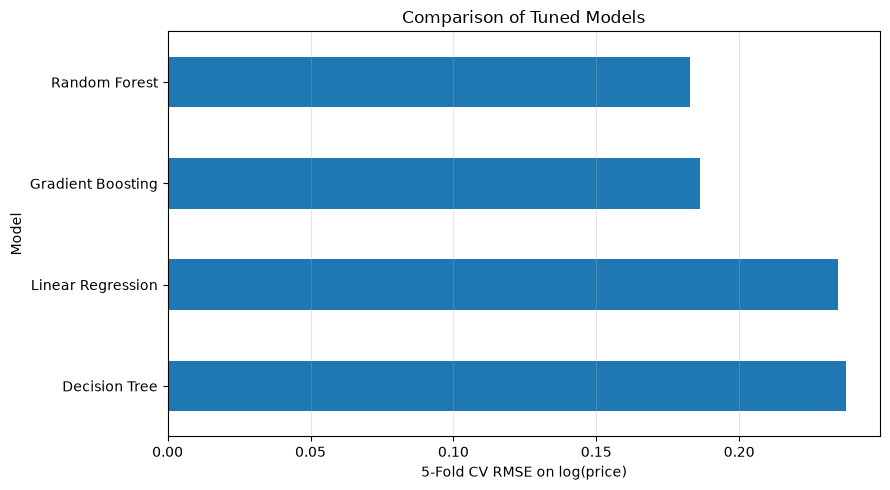

Chart saved to: D:\real-estate-price-prediction\reports\figures\11_cv_model_comparison.png


In [27]:
import matplotlib.pyplot as plt

ax = tuned_table["cv_rmse_log"].sort_values(
    ascending=False
).plot(
    kind="barh",
    figsize=(9, 5)
)

ax.set_xlabel("5-Fold CV RMSE on log(price)")
ax.set_ylabel("Model")
ax.set_title("Comparison of Tuned Models")
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

plot_path = (
    FIGURES_DIR / "11_cv_model_comparison.png"
)

plt.savefig(
    plot_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Chart saved to:", plot_path)

In [28]:
best_model_name = tuned_table["cv_rmse_log"].idxmin()

print("Best model by CV RMSE:", best_model_name)
print(
    "CV RMSE:",
    tuned_table.loc[best_model_name, "cv_rmse_log"]
)
print(
    "CV R²:",
    tuned_table.loc[best_model_name, "cv_r2"]
)
print(
    "Overfitting gap:",
    tuned_table.loc[best_model_name, "overfit_gap"]
)

Best model by CV RMSE: Random Forest
CV RMSE: 0.1828
CV R²: 0.9106
Overfitting gap: 0.0709


In [29]:
baseline_rmse = tuned_table.loc[
    "Linear Regression", "cv_rmse_log"
]

compare = tuned_table[["cv_rmse_log"]].copy()

compare["improvement_vs_linear_%"] = (
    (baseline_rmse - compare["cv_rmse_log"])
    / baseline_rmse
    * 100
).round(2)

display(compare.sort_values("cv_rmse_log"))

,cv_rmse_log,improvement_vs_linear_%
model,,
Random Forest,0.1828,22.05
Gradient Boosting,0.1862,20.60
Linear Regression,0.2345,0.00
Decision Tree,0.2374,-1.24


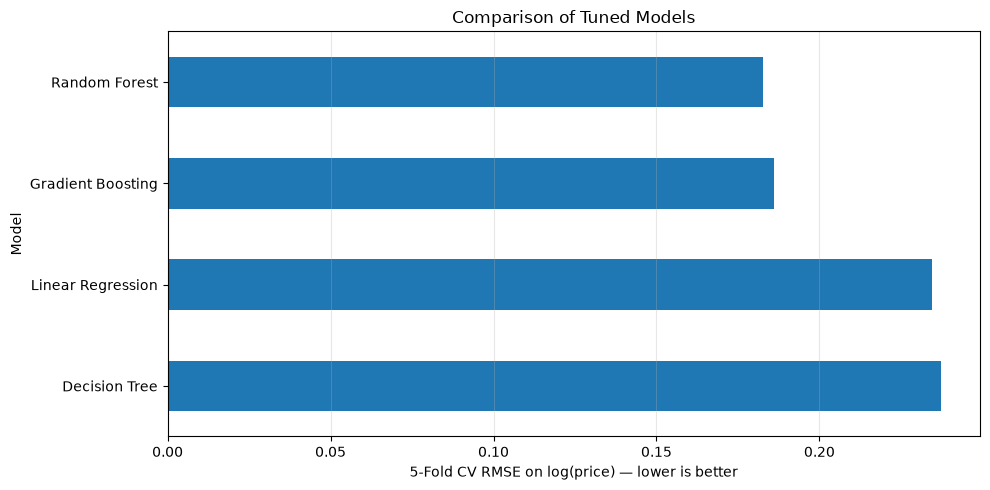

Chart saved successfully: D:\real-estate-price-prediction\reports\figures\11_cv_model_comparison.png


In [30]:
import matplotlib.pyplot as plt

# Sort models for a clear horizontal bar chart
plot_data = tuned_table["cv_rmse_log"].sort_values(
    ascending=False
)

ax = plot_data.plot(
    kind="barh",
    figsize=(10, 5)
)

ax.set_xlabel("5-Fold CV RMSE on log(price) — lower is better")
ax.set_ylabel("Model")
ax.set_title("Comparison of Tuned Models")
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()

# Save chart
FIGURES_DIR = (
    PROJECT_DIR / "reports" / "figures"
)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

plot_path = FIGURES_DIR / "11_cv_model_comparison.png"

plt.savefig(
    plot_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Chart saved successfully:", plot_path)

In [31]:
overfit_table = (
    tuned_table[
        ["train_r2", "cv_r2", "overfit_gap"]
    ]
    .sort_values("overfit_gap")
)

display(overfit_table)

,train_r2,cv_r2,overfit_gap
model,,,
Linear Regression,0.8615,0.8531,0.0084
Gradient Boosting,0.9385,0.9072,0.0314
Random Forest,0.9815,0.9106,0.0709
Decision Tree,0.9511,0.8493,0.1018


In [32]:
# Create report directories
REPORTS_DIR = PROJECT_DIR / "reports"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

# Save full model comparison
comparison_path = (
    REPORTS_DIR / "tuned_model_comparison.csv"
)

tuned_table.to_csv(comparison_path)

# Save improvement comparison
improvement_path = (
    REPORTS_DIR / "model_improvement_vs_linear.csv"
)

compare.to_csv(improvement_path)

print("Saved comparison table:", comparison_path)
print("Saved improvement table:", improvement_path)

Saved comparison table: D:\real-estate-price-prediction\reports\tuned_model_comparison.csv
Saved improvement table: D:\real-estate-price-prediction\reports\model_improvement_vs_linear.csv


In [33]:
best_model_name = tuned_table["cv_rmse_log"].idxmin()

best_cv_rmse = tuned_table.loc[
    best_model_name, "cv_rmse_log"
]

best_cv_r2 = tuned_table.loc[
    best_model_name, "cv_r2"
]

best_overfit_gap = tuned_table.loc[
    best_model_name, "overfit_gap"
]

linear_rmse = tuned_table.loc[
    "Linear Regression", "cv_rmse_log"
]

improvement = (
    (linear_rmse - best_cv_rmse)
    / linear_rmse
) * 100

print("=" * 55)
print("PART F: TUNED MODEL COMPARISON SUMMARY")
print("=" * 55)

print(f"Best model by CV RMSE: {best_model_name}")
print(f"CV RMSE: {best_cv_rmse:.4f}")
print(f"CV R²: {best_cv_r2:.4f}")
print(f"Training–CV R² gap: {best_overfit_gap:.4f}")
print(f"RMSE improvement over Linear Regression: {improvement:.2f}%")

print("\nModel ranking by CV RMSE:")

for rank, (name, row) in enumerate(
    tuned_table.sort_values("cv_rmse_log").iterrows(),
    start=1
):
    print(
        f"{rank}. {name}: "
        f"RMSE={row['cv_rmse_log']:.4f}, "
        f"R²={row['cv_r2']:.4f}"
    )

PART F: TUNED MODEL COMPARISON SUMMARY
Best model by CV RMSE: Random Forest
CV RMSE: 0.1828
CV R²: 0.9106
Training–CV R² gap: 0.0709
RMSE improvement over Linear Regression: 22.05%

Model ranking by CV RMSE:
1. Random Forest: RMSE=0.1828, R²=0.9106
2. Gradient Boosting: RMSE=0.1862, R²=0.9072
3. Linear Regression: RMSE=0.2345, R²=0.8531
4. Decision Tree: RMSE=0.2374, R²=0.8493


In [34]:
expected_files = [
    PROJECT_DIR / "reports" / "figures"
        / "11_cv_model_comparison.png",
    PROJECT_DIR / "reports"
        / "tuned_model_comparison.csv",
    PROJECT_DIR / "reports"
        / "model_improvement_vs_linear.csv",
]

print("PART F OUTPUT VERIFICATION")
print("=" * 45)

for path in expected_files:
    print(
        f"{'PASS' if path.exists() else 'MISSING'}: "
        f"{path}"
    )

PART F OUTPUT VERIFICATION
PASS: D:\real-estate-price-prediction\reports\figures\11_cv_model_comparison.png
PASS: D:\real-estate-price-prediction\reports\tuned_model_comparison.csv
PASS: D:\real-estate-price-prediction\reports\model_improvement_vs_linear.csv


In [36]:

display(
    tuned_table[
        ["train_r2", "cv_r2", "cv_r2_std", "cv_rmse_log", "overfit_gap"]
    ].sort_values("cv_rmse_log")
)


,train_r2,cv_r2,cv_r2_std,cv_rmse_log,overfit_gap
model,,,,,
Random Forest,0.9815,0.9106,0.0086,0.1828,0.0709
Gradient Boosting,0.9385,0.9072,0.0103,0.1862,0.0314
Linear Regression,0.8615,0.8531,0.0103,0.2345,0.0084
Decision Tree,0.9511,0.8493,0.0148,0.2374,0.1018


In [37]:
display(
    tuned_table[
        [
            "cv_r2",
            "cv_r2_std",
            "train_r2",
            "cv_rmse_log",
            "cv_mae_log",
            "overfit_gap",
        ]
    ].sort_values("cv_rmse_log")
)

,cv_r2,cv_r2_std,train_r2,cv_rmse_log,cv_mae_log,overfit_gap
model,,,,,,
Random Forest,0.9106,0.0086,0.9815,0.1828,0.1224,0.0709
Gradient Boosting,0.9072,0.0103,0.9385,0.1862,0.1327,0.0314
Linear Regression,0.8531,0.0103,0.8615,0.2345,0.1723,0.0084
Decision Tree,0.8493,0.0148,0.9511,0.2374,0.1568,0.1018


In [38]:
import json

notebook_path = PROJECT_DIR / "notebooks" / "06_model_training.ipynb"

with open(notebook_path, "r", encoding="utf-8") as f:
    nb = json.load(f)

for i, cell in enumerate(nb["cells"]):
    source = "".join(cell.get("source", []))

    if any(term in source.lower() for term in [
        "kfold(",
        "randomizedsearchcv(",
        "gridsearchcv(",
    ]):
        print(f"\n--- CELL {i} ---")
        print(source[:4000])


--- CELL 11 ---

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Cross-validation strategy created.")
print("Number of folds:", cv.get_n_splits())
print("Training samples:", len(X_train))



--- CELL 15 ---
searches = {
    "Linear Regression": GridSearchCV(
        estimator=models["Linear Regression"],
        param_grid=param_grids["Linear Regression"],
        scoring="neg_mean_absolute_error",
        cv=cv,
        n_jobs=-1,
        refit=True,
        return_train_score=True
    ),

    "Decision Tree": RandomizedSearchCV(
        estimator=models["Decision Tree"],
        param_distributions=param_grids["Decision Tree"],
        n_iter=30,
        scoring="neg_mean_absolute_error",
        cv=cv,
        random_state=42,
        n_jobs=-1,
        refit=True,
        return_train_score=True
    ),

    "Random Forest": RandomizedSearchCV(
        estimator=models["Random Forest"],
        param_distributions=param_grids["Random Forest"],
        n_

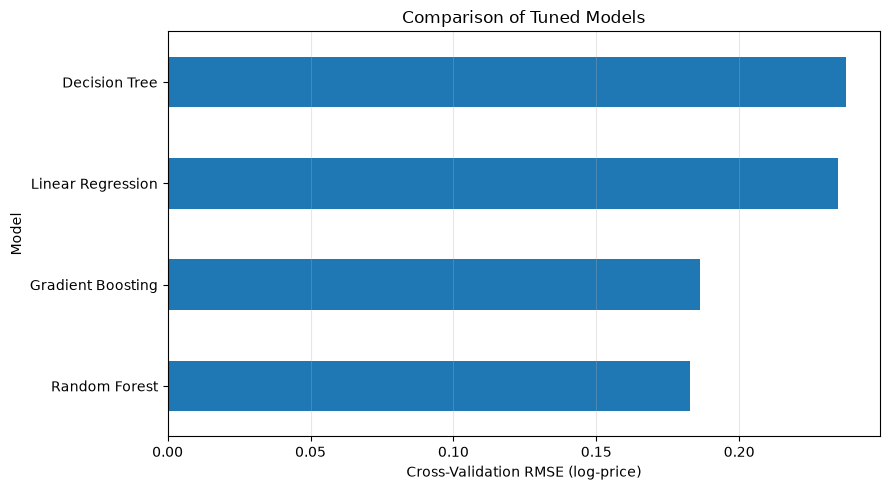

Chart saved to: D:\real-estate-price-prediction\reports\figures\11_cv_model_comparison.png


In [41]:

import matplotlib.pyplot as plt

FIGURES_DIR = PROJECT_DIR / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

plot_data = tuned_table.sort_values("cv_rmse_log", ascending=True)

ax = plot_data["cv_rmse_log"].plot(
    kind="barh",
    figsize=(9, 5)
)

ax.set_xlabel("Cross-Validation RMSE (log-price)")
ax.set_ylabel("Model")
ax.set_title("Comparison of Tuned Models")
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()

plot_path = FIGURES_DIR / "11_cv_model_comparison.png"
plt.savefig(plot_path, dpi=200, bbox_inches="tight")
plt.show()

print("Chart saved to:", plot_path)



In [42]:

REPORTS_DIR = PROJECT_DIR / "reports"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

tuned_table.to_csv(
    REPORTS_DIR / "tuned_model_comparison.csv"
)

compare.to_csv(
    REPORTS_DIR / "model_improvement_vs_linear.csv"
)

print("Comparison tables saved successfully.")

print("1.", REPORTS_DIR / "tuned_model_comparison.csv")
print("2.", REPORTS_DIR / "model_improvement_vs_linear.csv")



Comparison tables saved successfully.
1. D:\real-estate-price-prediction\reports\tuned_model_comparison.csv
2. D:\real-estate-price-prediction\reports\model_improvement_vs_linear.csv


In [43]:
from pathlib import Path

output_files = [
    PROJECT_DIR / "reports" / "figures" / "11_cv_model_comparison.png",
    PROJECT_DIR / "reports" / "tuned_model_comparison.csv",
    PROJECT_DIR / "reports" / "model_improvement_vs_linear.csv",
]

for file in output_files:
    print(f"{'✅ EXISTS' if file.exists() else '❌ MISSING'}: {file}")

✅ EXISTS: D:\real-estate-price-prediction\reports\figures\11_cv_model_comparison.png
✅ EXISTS: D:\real-estate-price-prediction\reports\tuned_model_comparison.csv
✅ EXISTS: D:\real-estate-price-prediction\reports\model_improvement_vs_linear.csv


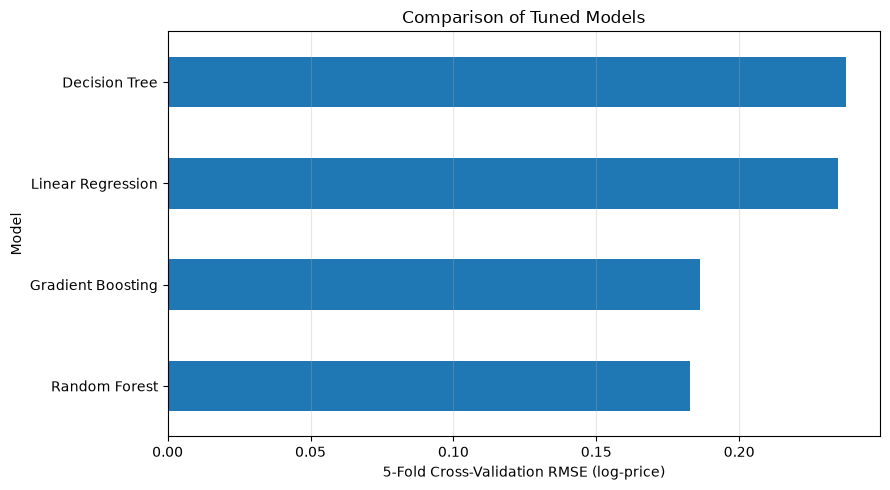

Chart saved to: D:\real-estate-price-prediction\reports\figures\11_cv_model_comparison.png


In [39]:
import matplotlib.pyplot as plt

FIGURES_DIR = PROJECT_DIR / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

plot_data = tuned_table.sort_values("cv_rmse_log", ascending=True)

ax = plot_data["cv_rmse_log"].plot(
    kind="barh",
    figsize=(9, 5)
)

ax.set_xlabel("5-Fold Cross-Validation RMSE (log-price)")
ax.set_ylabel("Model")
ax.set_title("Comparison of Tuned Models")
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()

plot_path = FIGURES_DIR / "11_cv_model_comparison.png"
plt.savefig(plot_path, dpi=200, bbox_inches="tight")
plt.show()

print("Chart saved to:", plot_path)

In [40]:
REPORTS_DIR = PROJECT_DIR / "reports"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

tuned_table.to_csv(
    REPORTS_DIR / "tuned_model_comparison.csv"
)

compare.to_csv(
    REPORTS_DIR / "model_improvement_vs_linear.csv"
)

print("Comparison tables saved successfully.")
print("Saved:", REPORTS_DIR / "tuned_model_comparison.csv")
print("Saved:", REPORTS_DIR / "model_improvement_vs_linear.csv")

Comparison tables saved successfully.
Saved: D:\real-estate-price-prediction\reports\tuned_model_comparison.csv
Saved: D:\real-estate-price-prediction\reports\model_improvement_vs_linear.csv


In [44]:
required_variables = [
    "searches",
    "models",
    "X_train",
    "train_df",
]

for var in required_variables:
    print(f"{var}: {'Available' if var in globals() else 'Missing'}")

searches: Missing
models: Missing
X_train: Available
train_df: Available


In [45]:
print("Available model-related files:")

for file in sorted((PROJECT_DIR / "models").glob("*")):
    if file.is_file():
        print(file.name)

Available model-related files:
.gitkeep
best_model_params.json
decision_tree_tuned.joblib
feature_config.json
final_model_metadata.json
final_price_model.joblib
gradient_boosting_tuned.joblib
linear_regression_tuned.joblib
model_config.json
preprocessing_config.json
random_forest_tuned.joblib
selected_final_model.joblib
selected_model_metadata.json


In [46]:
import joblib

MODELS_DIR = PROJECT_DIR / "models"

model_files = {
    "Linear Regression": "linear_regression_tuned.joblib",
    "Decision Tree": "decision_tree_tuned.joblib",
    "Random Forest": "random_forest_tuned.joblib",
    "Gradient Boosting": "gradient_boosting_tuned.joblib",
}

saved_models = {}

for name, filename in model_files.items():
    path = MODELS_DIR / filename

    if path.exists():
        saved_models[name] = joblib.load(path)
        print(f"Loaded: {name}")
    else:
        print(f"MISSING FILE: {path}")

print("\nModels loaded:", len(saved_models))

Loaded: Linear Regression
Loaded: Decision Tree
Loaded: Random Forest
Loaded: Gradient Boosting

Models loaded: 4


In [47]:
print("X_train shape:", X_train.shape)
print("train_df shape:", train_df.shape)

print("\nTarget available:", "price_lakhs" in train_df.columns)
print("Training rows match:", len(X_train) == len(train_df))

X_train shape: (5965, 15)
train_df shape: (5965, 19)

Target available: True
Training rows match: True


In [48]:
import json

notebook_path = PROJECT_DIR / "notebooks" / "06_model_training.ipynb"

with open(notebook_path, "r", encoding="utf-8") as f:
    nb = json.load(f)

for i, cell in enumerate(nb["cells"]):
    source = "".join(cell.get("source", []))

    if any(term in source for term in [
        "searches =",
        "GridSearchCV(",
        "RandomizedSearchCV(",
        "models =",
        "best_estimator_",
    ]):
        print(f"\n--- CELL {i} ---")
        print(source[:2500])


--- CELL 10 ---
models = {
    "Linear Regression": Pipeline([
        ("preprocessor", build_preprocessor(scale_numeric=True)),
        ("model", LinearRegression())
    ]),

    "Decision Tree": Pipeline([
        ("preprocessor", build_preprocessor(scale_numeric=False)),
        ("model", DecisionTreeRegressor(random_state=42))
    ]),

    "Random Forest": Pipeline([
        ("preprocessor", build_preprocessor(scale_numeric=False)),
        ("model", RandomForestRegressor(
            n_estimators=200,
            random_state=42,
            n_jobs=-1
        ))
    ]),

    "Gradient Boosting": Pipeline([
        ("preprocessor", build_preprocessor(scale_numeric=False)),
        ("model", GradientBoostingRegressor(random_state=42))
    ])
}

print("Models created:")
for name in models:
    print("-", name)



--- CELL 15 ---
searches = {
    "Linear Regression": GridSearchCV(
        estimator=models["Linear Regression"],
        param_grid=param_grids["Linear Regression"],
    

In [49]:
import joblib
import numpy as np

for name, model in saved_models.items():
    print(f"\n{name}")
    print("Pipeline steps:", model.named_steps.keys())
    print("Estimator:", model.named_steps["model"])

    sample_predictions = model.predict(X_train.head(5))
    print("Sample predictions:", np.round(sample_predictions, 4))


Linear Regression
Pipeline steps: dict_keys(['preprocessor', 'model'])
Estimator: LinearRegression()
Sample predictions: [5.774  5.6754 5.2789 5.1316 5.2631]

Decision Tree
Pipeline steps: dict_keys(['preprocessor', 'model'])
Estimator: DecisionTreeRegressor(max_depth=20, min_samples_split=20, random_state=42)
Sample predictions: [5.8992 5.9502 5.2693 5.0736 5.5773]

Random Forest
Pipeline steps: dict_keys(['preprocessor', 'model'])
Estimator: RandomForestRegressor(max_features=0.7, min_samples_split=5, n_estimators=400,
                      n_jobs=-1, random_state=42)
Sample predictions: [5.8971 5.9505 5.2805 5.0887 5.432 ]

Gradient Boosting
Pipeline steps: dict_keys(['preprocessor', 'model'])
Estimator: GradientBoostingRegressor(learning_rate=0.05, max_depth=4, min_samples_leaf=2,
                          min_samples_split=5, n_estimators=400,
                          random_state=42, subsample=0.9)
Sample predictions: [5.828  5.8105 5.3236 5.0448 5.4556]


In [50]:
import json

notebook_path = PROJECT_DIR / "notebooks" / "06_model_training.ipynb"

with open(notebook_path, "r", encoding="utf-8") as f:
    nb = json.load(f)

for i, cell in enumerate(nb["cells"]):
    source = "".join(cell.get("source", []))

    if any(term in source.lower() for term in [
        "search.fit(",
        "searches[name]",
        "y_train",
        "y_log",
        "log_price",
        "price_lakhs",
        "best_estimator_",
    ]):
        print(f"\n{'=' * 20} CELL {i} {'=' * 20}")
        print(source[:3500])


==================== CELL 4 ====================

import json
from pathlib import Path

PROJECT_DIR = Path(r"D:\real-estate-price-prediction")
MODELS_DIR = PROJECT_DIR / "models"
MODEL_DATA_PATH = PROJECT_DIR / "data" / "processed" / "model_data.csv"

MODELS_DIR.mkdir(parents=True, exist_ok=True)

NUM = [
    "bedroom_num",
    "bathroom_num",
    "balcony_num",
    "floor_num",
    "total_floor",
    "total_landmark_count",
    "area_sqft",
    "latitude",
    "longitude",
]

CAT = [
    "property_type",
    "owntype",
    "furnish",
    "facing",
    "age",
    "locality_grouped",
]

FEATURES = NUM + CAT

cfg = {
    "numeric_features": NUM,
    "categorical_features": CAT,
    "target": "log_price",
    "original_target": "price_lakhs",
    "identifier": "prop_id",
    "split_column": "split",
    "description": (
        "Core property features for Gurgaon real-estate price prediction. "
        "The target is log1p(price_lakhs)."
    ),
}

config_path = MODELS_DIR / "feature_conf

In [51]:
import numpy as np
import joblib

from sklearn.base import clone
from sklearn.compose import TransformedTargetRegressor

print("Required libraries imported successfully.")

Required libraries imported successfully.


In [52]:
final_models = {}

for name, base_pipe in saved_models.items():

    print(f"Fitting final model: {name}")

    # Clone the tuned pipeline so the original saved model remains unchanged
    final_model = TransformedTargetRegressor(
        regressor=clone(base_pipe),
        func=np.log1p,
        inverse_func=np.expm1
    )

    # Pass original prices in lakhs.
    # TransformedTargetRegressor applies log1p automatically.
    final_model.fit(
        X_train,
        train_df["price_lakhs"]
    )

    final_models[name] = final_model

    print(f"{name} fitted successfully.")

print("\nAll final models fitted successfully.")
print("Number of final models:", len(final_models))

Fitting final model: Linear Regression
Linear Regression fitted successfully.
Fitting final model: Decision Tree
Decision Tree fitted successfully.
Fitting final model: Random Forest
Random Forest fitted successfully.
Fitting final model: Gradient Boosting
Gradient Boosting fitted successfully.

All final models fitted successfully.
Number of final models: 4


In [53]:
for name, model in final_models.items():

    predictions = model.predict(X_train.head(5))

    print(f"\n{name}")
    print("Predictions (lakhs):", np.round(predictions, 2))

print("\nActual prices (lakhs):")
print(train_df["price_lakhs"].head(5).round(2).values)


Linear Regression
Predictions (lakhs): [320.82 290.62 195.16 168.29 192.07]

Decision Tree
Predictions (lakhs): [363.73 382.85 193.28 158.74 263.34]

Random Forest
Predictions (lakhs): [362.87 382.85 195.32 161.17 227.95]

Gradient Boosting
Predictions (lakhs): [338.68 332.8  204.13 154.21 233.07]

Actual prices (lakhs):
[360. 385. 195. 162. 220.]


In [54]:
test_prices = np.array([100.0, 250.0, 500.0])

log_prices = np.log1p(test_prices)
recovered_prices = np.expm1(log_prices)

print("Original prices:", test_prices)
print("Log prices:", np.round(log_prices, 4))
print("Recovered prices:", np.round(recovered_prices, 4))

assert np.allclose(test_prices, recovered_prices)

print("\nTransformation verified successfully.")

Original prices: [100. 250. 500.]
Log prices: [4.6151 5.5255 6.2166]
Recovered prices: [100. 250. 500.]

Transformation verified successfully.


In [55]:
for name, model in final_models.items():

    print(f"\n{name}")
    print("Model type:", type(model).__name__)
    print("Underlying pipeline:", type(model.regressor_).__name__)
    print("Target transformation:", model.func.__name__)
    print("Inverse transformation:", model.inverse_func.__name__)


Linear Regression
Model type: TransformedTargetRegressor
Underlying pipeline: Pipeline
Target transformation: log1p
Inverse transformation: expm1

Decision Tree
Model type: TransformedTargetRegressor
Underlying pipeline: Pipeline
Target transformation: log1p
Inverse transformation: expm1

Random Forest
Model type: TransformedTargetRegressor
Underlying pipeline: Pipeline
Target transformation: log1p
Inverse transformation: expm1

Gradient Boosting
Model type: TransformedTargetRegressor
Underlying pipeline: Pipeline
Target transformation: log1p
Inverse transformation: expm1


In [56]:
MODELS_DIR = PROJECT_DIR / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

for name, model in final_models.items():

    filename = name.lower().replace(" ", "_") + "_final.joblib"
    model_path = MODELS_DIR / filename

    joblib.dump(model, model_path)

    print(f"Saved {name}: {model_path}")

print("\nAll final models saved successfully.")

Saved Linear Regression: D:\real-estate-price-prediction\models\linear_regression_final.joblib
Saved Decision Tree: D:\real-estate-price-prediction\models\decision_tree_final.joblib
Saved Random Forest: D:\real-estate-price-prediction\models\random_forest_final.joblib
Saved Gradient Boosting: D:\real-estate-price-prediction\models\gradient_boosting_final.joblib

All final models saved successfully.


In [57]:
saved_model_path = MODELS_DIR / "random_forest_final.joblib"

loaded_model = joblib.load(saved_model_path)

predictions = loaded_model.predict(X_train.head(5))

print("Loaded model:", type(loaded_model).__name__)
print("Predictions in lakhs:", np.round(predictions, 2))

Loaded model: TransformedTargetRegressor
Predictions in lakhs: [362.87 382.85 195.32 161.17 227.95]


In [58]:
for name, model in final_models.items():
    predictions = model.predict(X_train.head(5))

    print(f"\n{name}")
    print("Predictions (lakhs):", np.round(predictions, 2))

print("\nActual prices (lakhs):")
print(train_df["price_lakhs"].head(5).round(2).values)


Linear Regression
Predictions (lakhs): [320.82 290.62 195.16 168.29 192.07]

Decision Tree
Predictions (lakhs): [363.73 382.85 193.28 158.74 263.34]

Random Forest
Predictions (lakhs): [362.87 382.85 195.32 161.17 227.95]

Gradient Boosting
Predictions (lakhs): [338.68 332.8  204.13 154.21 233.07]

Actual prices (lakhs):
[360. 385. 195. 162. 220.]


In [59]:
test_prices = np.array([100.0, 250.0, 500.0])

log_prices = np.log1p(test_prices)
recovered_prices = np.expm1(log_prices)

print("Original prices:", test_prices)
print("Log prices:", np.round(log_prices, 4))
print("Recovered prices:", np.round(recovered_prices, 4))

assert np.allclose(test_prices, recovered_prices)

print("\nTarget conversion verified successfully.")

Original prices: [100. 250. 500.]
Log prices: [4.6151 5.5255 6.2166]
Recovered prices: [100. 250. 500.]

Target conversion verified successfully.


In [60]:
for name, model in final_models.items():
    print(f"\n{name}")
    print("Model type:", type(model).__name__)
    print("Target transformation:", model.func.__name__)
    print("Inverse transformation:", model.inverse_func.__name__)


Linear Regression
Model type: TransformedTargetRegressor
Target transformation: log1p
Inverse transformation: expm1

Decision Tree
Model type: TransformedTargetRegressor
Target transformation: log1p
Inverse transformation: expm1

Random Forest
Model type: TransformedTargetRegressor
Target transformation: log1p
Inverse transformation: expm1

Gradient Boosting
Model type: TransformedTargetRegressor
Target transformation: log1p
Inverse transformation: expm1


In [61]:
MODELS_DIR = PROJECT_DIR / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

for name, model in final_models.items():
    filename = name.lower().replace(" ", "_") + "_final.joblib"
    model_path = MODELS_DIR / filename

    joblib.dump(model, model_path)

    print(f"Saved {name}: {model_path}")

print("\nAll final models saved successfully.")

Saved Linear Regression: D:\real-estate-price-prediction\models\linear_regression_final.joblib
Saved Decision Tree: D:\real-estate-price-prediction\models\decision_tree_final.joblib
Saved Random Forest: D:\real-estate-price-prediction\models\random_forest_final.joblib
Saved Gradient Boosting: D:\real-estate-price-prediction\models\gradient_boosting_final.joblib

All final models saved successfully.


In [62]:
saved_model_path = MODELS_DIR / "random_forest_final.joblib"

loaded_model = joblib.load(saved_model_path)

predictions = loaded_model.predict(X_train.head(5))

print("Loaded model:", type(loaded_model).__name__)
print("Predictions in lakhs:", np.round(predictions, 2))

Loaded model: TransformedTargetRegressor
Predictions in lakhs: [362.87 382.85 195.32 161.17 227.95]


In [63]:
expected_files = [
    "linear_regression_final.joblib",
    "decision_tree_final.joblib",
    "random_forest_final.joblib",
    "gradient_boosting_final.joblib",
]

for filename in expected_files:
    path = MODELS_DIR / filename
    print(f"{'✅ EXISTS' if path.exists() else '❌ MISSING'}: {filename}")

✅ EXISTS: linear_regression_final.joblib
✅ EXISTS: decision_tree_final.joblib
✅ EXISTS: random_forest_final.joblib
✅ EXISTS: gradient_boosting_final.joblib


In [66]:
required_variables = [
    "PROJECT_DIR",
    "final_models",
    "joblib",
    "json",
    "sklearn"
]

for var in required_variables:
    print(f"{var}: {'Available' if var in globals() else 'Missing'}")

PROJECT_DIR: Available
final_models: Available
joblib: Available
json: Available
sklearn: Available


In [65]:
import json
import joblib
import sklearn

In [67]:
from pathlib import Path

PROJECT_DIR = Path(r"D:\real-estate-price-prediction")

In [68]:
from pathlib import Path

MODELS_DIR = PROJECT_DIR / "models"
REPORTS_DIR = PROJECT_DIR / "reports"

MODELS_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

print("Models directory:", MODELS_DIR)
print("Reports directory:", REPORTS_DIR)

print("\nFolder setup completed successfully.")

Models directory: D:\real-estate-price-prediction\models
Reports directory: D:\real-estate-price-prediction\reports

Folder setup completed successfully.


In [69]:
import joblib

def slug(name):
    return (
        name.lower()
        .replace(" ", "_")
        .replace("(", "")
        .replace(")", "")
    )

for name, model in final_models.items():
    filename = f"{slug(name)}.pkl"
    model_path = MODELS_DIR / filename

    joblib.dump(model, model_path)

    print(f"Saved {name}: {model_path.name}")

print("\nAll final models saved successfully.")

Saved Linear Regression: linear_regression.pkl
Saved Decision Tree: decision_tree.pkl
Saved Random Forest: random_forest.pkl
Saved Gradient Boosting: gradient_boosting.pkl

All final models saved successfully.


In [70]:
expected_model_files = [
    "linear_regression.pkl",
    "decision_tree.pkl",
    "random_forest.pkl",
    "gradient_boosting.pkl"
]

for filename in expected_model_files:
    path = MODELS_DIR / filename

    if path.exists():
        size_mb = path.stat().st_size / (1024 * 1024)
        print(f"✅ EXISTS: {filename} ({size_mb:.2f} MB)")
    else:
        print(f"❌ MISSING: {filename}")

✅ EXISTS: linear_regression.pkl (0.01 MB)
✅ EXISTS: decision_tree.pkl (0.11 MB)
✅ EXISTS: random_forest.pkl (89.86 MB)
✅ EXISTS: gradient_boosting.pkl (0.85 MB)


In [71]:
import json
import numpy as np

best_params = {}

for name, model in final_models.items():
    estimator = model.regressor_.named_steps["model"]
    params = estimator.get_params(deep=False)

    best_params[name] = {
        key: (
            value.item()
            if isinstance(value, np.generic)
            else value
            if isinstance(value, (int, float, str, bool, type(None)))
            else str(value)
        )
        for key, value in params.items()
    }

params_path = MODELS_DIR / "best_params.json"

with open(params_path, "w", encoding="utf-8") as file:
    json.dump(best_params, file, indent=2)

print("Best model parameters saved to:", params_path)
print("\nModels included:", list(best_params.keys()))

Best model parameters saved to: D:\real-estate-price-prediction\models\best_params.json

Models included: ['Linear Regression', 'Decision Tree', 'Random Forest', 'Gradient Boosting']


In [72]:
print("searches available:", "searches" in globals())

searches available: False


In [73]:
FEATURE_CONFIG_PATH = MODELS_DIR / "feature_config.json"

print("Feature config exists:", FEATURE_CONFIG_PATH.exists())

Feature config exists: True


In [74]:
import json
import sklearn

with open(FEATURE_CONFIG_PATH, "r", encoding="utf-8") as file:
    feature_config = json.load(file)

print(json.dumps(feature_config, indent=2))

{
  "numeric_features": [
    "bedroom_num",
    "bathroom_num",
    "balcony_num",
    "floor_num",
    "total_floor",
    "total_landmark_count",
    "area_sqft",
    "latitude",
    "longitude"
  ],
  "categorical_features": [
    "property_type",
    "owntype",
    "furnish",
    "facing",
    "age",
    "locality_grouped"
  ],
  "target": "log_price",
  "original_target": "price_lakhs",
  "identifier": "prop_id",
  "split_column": "split",
  "description": "Core property features for Gurgaon real-estate price prediction. The target is log1p(price_lakhs)."
}


In [75]:
numeric_features = feature_config["numeric_features"]
categorical_features = feature_config["categorical_features"]

metadata = {
    "sklearn_version": sklearn.__version__,
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "target": "price_lakhs",
    "target_transform": "log1p / expm1",
    "train_rows": int(len(X_train)),
    "models": list(final_models.keys()),
    "model_type": "TransformedTargetRegressor",
    "prediction_unit": "lakhs"
}

metadata_path = MODELS_DIR / "model_meta.json"

with open(metadata_path, "w", encoding="utf-8") as file:
    json.dump(metadata, file, indent=2)

print("Model metadata saved to:", metadata_path)
print("\nMetadata saved successfully.")

Model metadata saved to: D:\real-estate-price-prediction\models\model_meta.json

Metadata saved successfully.


In [76]:
with open(metadata_path, "r", encoding="utf-8") as file:
    saved_metadata = json.load(file)

print(json.dumps(saved_metadata, indent=2))

{
  "sklearn_version": "1.9.1",
  "numeric_features": [
    "bedroom_num",
    "bathroom_num",
    "balcony_num",
    "floor_num",
    "total_floor",
    "total_landmark_count",
    "area_sqft",
    "latitude",
    "longitude"
  ],
  "categorical_features": [
    "property_type",
    "owntype",
    "furnish",
    "facing",
    "age",
    "locality_grouped"
  ],
  "target": "price_lakhs",
  "target_transform": "log1p / expm1",
  "train_rows": 5965,
  "models": [
    "Linear Regression",
    "Decision Tree",
    "Random Forest",
    "Gradient Boosting"
  ],
  "model_type": "TransformedTargetRegressor",
  "prediction_unit": "lakhs"
}


In [77]:
with open(metadata_path, "r", encoding="utf-8") as file:
    saved_metadata = json.load(file)

print(json.dumps(saved_metadata, indent=2))

{
  "sklearn_version": "1.9.1",
  "numeric_features": [
    "bedroom_num",
    "bathroom_num",
    "balcony_num",
    "floor_num",
    "total_floor",
    "total_landmark_count",
    "area_sqft",
    "latitude",
    "longitude"
  ],
  "categorical_features": [
    "property_type",
    "owntype",
    "furnish",
    "facing",
    "age",
    "locality_grouped"
  ],
  "target": "price_lakhs",
  "target_transform": "log1p / expm1",
  "train_rows": 5965,
  "models": [
    "Linear Regression",
    "Decision Tree",
    "Random Forest",
    "Gradient Boosting"
  ],
  "model_type": "TransformedTargetRegressor",
  "prediction_unit": "lakhs"
}


In [78]:
print("tuned_table available:", "tuned_table" in globals())
print("baseline_table available:", "baseline_table" in globals())

tuned_table available: True
baseline_table available: False


In [79]:
expected_report_files = [
    "tuned_model_comparison.csv",
    "model_improvement_vs_linear.csv"
]

for filename in expected_report_files:
    path = REPORTS_DIR / filename
    print(f"{'✅ EXISTS' if path.exists() else '❌ MISSING'}: {filename}")

✅ EXISTS: tuned_model_comparison.csv
✅ EXISTS: model_improvement_vs_linear.csv


In [80]:
import shutil

source_tuned = REPORTS_DIR / "tuned_model_comparison.csv"
source_baseline = REPORTS_DIR / "model_improvement_vs_linear.csv"

if source_tuned.exists():
    shutil.copy2(
        source_tuned,
        REPORTS_DIR / "cv_comparison.csv"
    )
    print("Created cv_comparison.csv")

if source_baseline.exists():
    shutil.copy2(
        source_baseline,
        REPORTS_DIR / "cv_baseline.csv"
    )
    print("Created cv_baseline.csv")

Created cv_comparison.csv
Created cv_baseline.csv


In [82]:
import pandas as pd

csv_files = [
    "cv_comparison.csv",
    "cv_baseline.csv"
]

for filename in csv_files:
    path = REPORTS_DIR / filename

    if path.exists():
        df = pd.read_csv(path)
        print(f"\n✅ {filename}")
        print("Shape:", df.shape)
        print(df.head())
    else:
        print(f"\n❌ MISSING: {filename}")


✅ cv_comparison.csv
Shape: (4, 7)
               model   cv_r2  cv_r2_std  train_r2  cv_rmse_log  cv_mae_log  \
0      Random Forest  0.9106     0.0086    0.9815       0.1828      0.1224   
1  Gradient Boosting  0.9072     0.0103    0.9385       0.1862      0.1327   
2  Linear Regression  0.8531     0.0103    0.8615       0.2345      0.1723   
3      Decision Tree  0.8493     0.0148    0.9511       0.2374      0.1568   

   overfit_gap  
0       0.0709  
1       0.0314  
2       0.0084  
3       0.1018  

✅ cv_baseline.csv
Shape: (4, 3)
               model  cv_rmse_log  improvement_vs_linear_%
0      Random Forest       0.1828                    22.05
1  Gradient Boosting       0.1862                    20.60
2  Linear Regression       0.2345                     0.00
3      Decision Tree       0.2374                    -1.24


In [83]:
import joblib
import numpy as np

saved_model_path = MODELS_DIR / "random_forest.pkl"

loaded_model = joblib.load(saved_model_path)

sample_predictions = loaded_model.predict(X_train.head(5))

print("Loaded model:", type(loaded_model).__name__)
print("Predictions in lakhs:", np.round(sample_predictions, 2))

Loaded model: TransformedTargetRegressor
Predictions in lakhs: [362.87 382.85 195.32 161.17 227.95]


In [84]:
import sklearn

print("Current scikit-learn version:", sklearn.__version__)

Current scikit-learn version: 1.9.1


In [85]:
GITIGNORE_PATH = PROJECT_DIR / ".gitignore"

if GITIGNORE_PATH.exists():
    print(GITIGNORE_PATH.read_text(encoding="utf-8"))
else:
    print(".gitignore was not found.")

# Python virtual environment
venv/

# Python cache files
__pycache__/
*.pyc

# Jupyter Notebook checkpoints
.ipynb_checkpoints/

# Environment variables and secrets
.env

# Operating system files
.DS_Store

# Large datasets
data/raw/*
data/processed/*

# Keep dataset directories in Git
!data/raw/.gitkeep
!data/processed/.gitkeep

# Trained machine learning models
models/*.pkl

# Large OpenStreetMap source data
data/external/*.osm.pbf


In [86]:
expected_files = [
    MODELS_DIR / "linear_regression.pkl",
    MODELS_DIR / "decision_tree.pkl",
    MODELS_DIR / "random_forest.pkl",
    MODELS_DIR / "gradient_boosting.pkl",
    MODELS_DIR / "best_params.json",
    MODELS_DIR / "model_meta.json",
    REPORTS_DIR / "cv_comparison.csv",
    REPORTS_DIR / "cv_baseline.csv"
]

all_exist = True

for path in expected_files:
    exists = path.exists()

    print(
        f"{'✅ EXISTS' if exists else '❌ MISSING'}: "
        f"{path.relative_to(PROJECT_DIR)}"
    )

    if not exists:
        all_exist = False

print("\n" + ("🎉 PART H COMPLETE!" if all_exist
               else "⚠️ Some files are missing. Review the steps above."))

✅ EXISTS: models\linear_regression.pkl
✅ EXISTS: models\decision_tree.pkl
✅ EXISTS: models\random_forest.pkl
✅ EXISTS: models\gradient_boosting.pkl
✅ EXISTS: models\best_params.json
✅ EXISTS: models\model_meta.json
✅ EXISTS: reports\cv_comparison.csv
✅ EXISTS: reports\cv_baseline.csv

🎉 PART H COMPLETE!


In [87]:
from pathlib import Path

PROJECT_DIR = Path(r"D:\real-estate-price-prediction")

MODELS_DIR = PROJECT_DIR / "models"
DATA_DIR = PROJECT_DIR / "data" / "processed"
REPORTS_DIR = PROJECT_DIR / "reports"

required_files = [
    DATA_DIR / "model_data.csv",
    MODELS_DIR / "feature_config.json",
    MODELS_DIR / "model_meta.json",
]

for path in required_files:
    print(
        f"{'✅ EXISTS' if path.exists() else '❌ MISSING'}: "
        f"{path.relative_to(PROJECT_DIR)}"
    )

✅ EXISTS: data\processed\model_data.csv
✅ EXISTS: models\feature_config.json
✅ EXISTS: models\model_meta.json


In [88]:
import pandas as pd
import json

DATA_PATH = DATA_DIR / "model_data.csv"
CONFIG_PATH = MODELS_DIR / "feature_config.json"

df = pd.read_csv(DATA_PATH)

with open(CONFIG_PATH, "r", encoding="utf-8") as file:
    feature_config = json.load(file)

print("Dataset shape:", df.shape)
print("\nDataset columns:")
print(df.columns.tolist())

print("\nFeature configuration:")
print(json.dumps(feature_config, indent=2))

Dataset shape: (7457, 19)

Dataset columns:
['prop_id', 'bedroom_num', 'bathroom_num', 'balcony_num', 'floor_num', 'total_floor', 'total_landmark_count', 'area_sqft', 'property_type', 'owntype', 'furnish', 'facing', 'age', 'locality_grouped', 'latitude', 'longitude', 'price_lakhs', 'log_price', 'split']

Feature configuration:
{
  "numeric_features": [
    "bedroom_num",
    "bathroom_num",
    "balcony_num",
    "floor_num",
    "total_floor",
    "total_landmark_count",
    "area_sqft",
    "latitude",
    "longitude"
  ],
  "categorical_features": [
    "property_type",
    "owntype",
    "furnish",
    "facing",
    "age",
    "locality_grouped"
  ],
  "target": "log_price",
  "original_target": "price_lakhs",
  "identifier": "prop_id",
  "split_column": "split",
  "description": "Core property features for Gurgaon real-estate price prediction. The target is log1p(price_lakhs)."
}


In [89]:
NUM = feature_config["numeric_features"]
CAT = feature_config["categorical_features"]

print("Numeric features:", len(NUM))
print("Categorical features:", len(CAT))

print("\nMissing numeric columns:")
print([col for col in NUM if col not in df.columns])

print("\nMissing categorical columns:")
print([col for col in CAT if col not in df.columns])

Numeric features: 9
Categorical features: 6

Missing numeric columns:
[]

Missing categorical columns:
[]


In [90]:
feature_columns = NUM + CAT

missing_values = df[feature_columns].isna().sum()

print("Missing values by feature:")
print(missing_values[missing_values > 0])

print("\nTotal missing feature values:", int(missing_values.sum()))

Missing values by feature:
balcony_num               3
floor_num               754
total_floor               2
total_landmark_count      2
dtype: int64

Total missing feature values: 761


In [91]:
import joblib

model_path = MODELS_DIR / "random_forest_final.joblib"

if model_path.exists():
    model = joblib.load(model_path)

    print("Outer model:", type(model).__name__)
    print("Inner pipeline:", type(model.regressor_).__name__)
    print("\nPipeline steps:")

    for step_name, step in model.regressor_.steps:
        print(step_name, "->", type(step).__name__)
else:
    print("random_forest_final.joblib was not found.")

Outer model: TransformedTargetRegressor
Inner pipeline: Pipeline

Pipeline steps:
preprocessor -> ColumnTransformer
model -> RandomForestRegressor


In [92]:
import joblib

model_path = MODELS_DIR / "random_forest_final.joblib"
model = joblib.load(model_path)

preprocessor = model.regressor_.named_steps["preprocessor"]

print(preprocessor)

ColumnTransformer(transformers=[('numeric',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median'))]),
                                 ['bedroom_num', 'bathroom_num', 'balcony_num',
                                  'floor_num', 'total_floor',
                                  'total_landmark_count', 'area_sqft',
                                  'latitude', 'longitude']),
                                ('categorical',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehot',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['property_type', 'owntype', 'furnish',
                                  'facing', 'age', 'locality_grouped'])])


In [93]:
from sklearn.impute import SimpleImputer

preprocessor = model.regressor_.named_steps["preprocessor"]

for name, transformer, columns in preprocessor.transformers_:
    print(f"\nTransformer: {name}")
    print("Columns:", list(columns) if not isinstance(columns, str) else columns)

    if hasattr(transformer, "named_steps"):
        for step_name, step in transformer.named_steps.items():
            print(f"  {step_name}: {type(step).__name__}")

            if isinstance(step, SimpleImputer):
                print("  Imputation strategy:", step.strategy)
                print("  Statistics:", step.statistics_)


Transformer: numeric
Columns: ['bedroom_num', 'bathroom_num', 'balcony_num', 'floor_num', 'total_floor', 'total_landmark_count', 'area_sqft', 'latitude', 'longitude']
  imputer: SimpleImputer
  Imputation strategy: median
  Statistics: [   3.           4.           3.           5.          14.
   14.        2217.          28.4256506   77.053568 ]

Transformer: categorical
Columns: ['property_type', 'owntype', 'furnish', 'facing', 'age', 'locality_grouped']
  imputer: SimpleImputer
  Imputation strategy: most_frequent
  Statistics: ['Residential Apartment' 1 4 5 1 'Sector 65 Gurgaon']
  onehot: OneHotEncoder


In [94]:
import numpy as np

sample = df.loc[
    df["split"] == "train",
    NUM + CAT
].head(5)

predictions = model.predict(sample)

print("Predictions:", np.round(predictions, 2))
print("All predictions finite:", np.isfinite(predictions).all())

Predictions: [362.87 382.85 195.32 161.17 227.95]
All predictions finite: True


In [95]:
X_all = df[NUM + CAT]

try:
    predictions = model.predict(X_all)

    print("✅ Model successfully predicted all rows.")
    print("Number of predictions:", len(predictions))
    print("All predictions finite:", np.isfinite(predictions).all())

except Exception as e:
    print("❌ Model prediction failed.")
    print("Error:", repr(e))

✅ Model successfully predicted all rows.
Number of predictions: 7457
All predictions finite: True


In [96]:
print("Missing floor_num:", df["floor_num"].isna().sum())
print("Total rows:", len(df))
print(
    "Percentage missing:",
    round(df["floor_num"].isna().mean() * 100, 2),
    "%"
)

Missing floor_num: 754
Total rows: 7457
Percentage missing: 10.11 %


In [97]:
display(
    df.loc[
        df["floor_num"].isna(),
        ["floor_num", "total_floor", "property_type", "price_lakhs"]
    ].head(10)
)

,floor_num,total_floor,property_type,price_lakhs
5,NaN,3.0,Independent/Builder Floor,220.0
24,NaN,4.0,Independent House/Villa,150.0
25,NaN,1.0,Independent House/Villa,1800.0
27,NaN,15.0,Independent House/Villa,166.0
86,NaN,2.0,Independent House/Villa,800.0
87,NaN,2.0,Independent House/Villa,1070.0
92,NaN,4.0,Independent/Builder Floor,260.0
102,NaN,3.0,Independent House/Villa,130.0
118,NaN,3.0,Independent House/Villa,450.0
169,NaN,2.0,Independent House/Villa,360.0


In [98]:
floor_analysis = (
    df.groupby("property_type")
    .agg(
        total_properties=("floor_num", "size"),
        missing_floor=("floor_num", lambda x: x.isna().sum()),
        missing_percentage=("floor_num", lambda x: x.isna().mean() * 100)
    )
    .sort_values("missing_floor", ascending=False)
)

display(floor_analysis.round(2))

,total_properties,missing_floor,missing_percentage
property_type,,,
Independent House/Villa,433,433,100.00
Independent/Builder Floor,2274,194,8.53
Residential Apartment,4750,127,2.67


In [99]:
missing_floor_summary = (
    df.assign(floor_num_missing=df["floor_num"].isna())
    .groupby("floor_num_missing")
    .agg(
        properties=("price_lakhs", "size"),
        average_total_floor=("total_floor", "mean"),
        median_total_floor=("total_floor", "median"),
        average_price_lakhs=("price_lakhs", "mean"),
        median_price_lakhs=("price_lakhs", "median")
    )
)

display(missing_floor_summary.round(2))

,properties,average_total_floor,median_total_floor,average_price_lakhs,median_price_lakhs
floor_num_missing,,,,,
False,6703,16.37,15.0,325.62,245.0
True,754,4.91,3.0,539.21,397.0


In [100]:
import json

with open("../models/feature_config.json", "r") as f:
    feature_config = json.load(f)

print("Numeric features:")
print(feature_config["numeric_features"])

print("\nCategorical features:")
print(feature_config["categorical_features"])

FileNotFoundError: [Errno 2] No such file or directory: '../models/feature_config.json'

In [101]:
import os

print("Current working directory:")
print(os.getcwd())

Current working directory:
d:\


In [102]:
from pathlib import Path

project_path = Path(r"D:\real-estate-price-prediction")
config_path = project_path / "models" / "feature_config.json"

print("File exists:", config_path.exists())
print("Expected path:", config_path)

File exists: True
Expected path: D:\real-estate-price-prediction\models\feature_config.json


In [103]:
import json

with open(config_path, "r", encoding="utf-8") as f:
    feature_config = json.load(f)

print("Numeric features:")
print(feature_config["numeric_features"])

print("\nCategorical features:")
print(feature_config["categorical_features"])

Numeric features:
['bedroom_num', 'bathroom_num', 'balcony_num', 'floor_num', 'total_floor', 'total_landmark_count', 'area_sqft', 'latitude', 'longitude']

Categorical features:
['property_type', 'owntype', 'furnish', 'facing', 'age', 'locality_grouped']


In [104]:
print("DataFrame shape:", df.shape)

print("\nDataFrame columns:")
print(df.columns.tolist())

print("\nMissing floor_num values:")
print(df["floor_num"].isna().sum())

DataFrame shape: (7457, 19)

DataFrame columns:
['prop_id', 'bedroom_num', 'bathroom_num', 'balcony_num', 'floor_num', 'total_floor', 'total_landmark_count', 'area_sqft', 'property_type', 'owntype', 'furnish', 'facing', 'age', 'locality_grouped', 'latitude', 'longitude', 'price_lakhs', 'log_price', 'split']

Missing floor_num values:
754


In [105]:
for name in ["X_train", "X_test", "y_train", "y_test"]:
    if name in globals():
        obj = globals()[name]
        print(f"{name}: {obj.shape}")
    else:
        print(f"{name}: not found")

X_train: (5965, 15)
X_test: not found
y_train: not found
y_test: not found


In [106]:

# Find variables that may contain the training and testing data
for name in sorted(globals()):
    if any(key in name.lower() for key in ["train", "test", "target", "split", "model"]):
        obj = globals()[name]
        if hasattr(obj, "shape"):
            print(f"{name}: shape={obj.shape}, type={type(obj).__name__}")
        elif isinstance(obj, dict):
            print(f"{name}: dictionary with keys={list(obj.keys())}")



X_train: shape=(5965, 15), type=DataFrame
final_models: dictionary with keys=['Linear Regression', 'Decision Tree', 'Random Forest', 'Gradient Boosting']
model_files: dictionary with keys=['Linear Regression', 'Decision Tree', 'Random Forest', 'Gradient Boosting']
saved_models: dictionary with keys=['Linear Regression', 'Decision Tree', 'Random Forest', 'Gradient Boosting']
test_prices: shape=(3,), type=ndarray
train_df: shape=(5965, 19), type=DataFrame


In [107]:

print("Training dataset columns:")
print(train_df.columns.tolist())

print("\nFirst five rows:")
display(train_df.head())

print("\nMissing floor_num values in train_df:")
print(train_df["floor_num"].isna().sum())



Training dataset columns:
['prop_id', 'bedroom_num', 'bathroom_num', 'balcony_num', 'floor_num', 'total_floor', 'total_landmark_count', 'area_sqft', 'property_type', 'owntype', 'furnish', 'facing', 'age', 'locality_grouped', 'latitude', 'longitude', 'price_lakhs', 'log_price', 'split']

First five rows:


,prop_id,bedroom_num,bathroom_num,balcony_num,floor_num,total_floor,total_landmark_count,area_sqft,property_type,owntype,furnish,facing,age,locality_grouped,latitude,longitude,price_lakhs,log_price,split
1,T71585466,4.0,4,3.0,7.0,29.0,9.0,2870.0,Residential Apartment,1,4,1,1,Sector 81 Gurgaon,28.388907,76.951328,360.0,5.888878,train
2,I71493958,3.0,3,3.0,14.0,28.0,8.0,2802.0,Residential Apartment,1,4,0,1,Sector 112 Gurgaon,28.518677,77.015115,385.0,5.955837,train
3,X71361930,3.0,4,4.0,4.0,27.0,14.0,2290.0,Residential Apartment,1,4,2,1,Sector 104 Gurgaon,28.478440,76.986110,195.0,5.278115,train
4,N71483500,2.0,2,3.0,12.0,30.0,13.0,1400.0,Residential Apartment,1,2,3,6,Sector 74 Gurgaon,28.416400,77.012620,162.0,5.093750,train
5,S69432236,3.0,3,3.0,NaN,3.0,11.0,2727.0,Independent/Builder Floor,1,4,6,1,Sector 102 Gurgaon,28.474861,76.976292,220.0,5.398163,train



Missing floor_num values in train_df:
602


In [108]:
print("Columns containing target or split information:")

for col in train_df.columns:
    if any(word in col.lower() for word in ["price", "target", "split", "log"]):
        print(f"{col}: {train_df[col].head(3).tolist()}")

Columns containing target or split information:
price_lakhs: [360.0, 385.0, 195.0]
log_price: [5.8888779583328805, 5.955837369464831, 5.278114659230517]
split: ['train', 'train', 'train']


In [109]:
for name, model in final_models.items():
    print(f"\n{name}")
    print("Model type:", type(model).__name__)

    if hasattr(model, "n_features_in_"):
        print("Expected input features:", model.n_features_in_)

    if hasattr(model, "regressor_"):
        print("Underlying fitted regressor:", type(model.regressor_).__name__)


Linear Regression
Model type: TransformedTargetRegressor
Expected input features: 15
Underlying fitted regressor: Pipeline

Decision Tree
Model type: TransformedTargetRegressor
Expected input features: 15
Underlying fitted regressor: Pipeline

Random Forest
Model type: TransformedTargetRegressor
Expected input features: 15
Underlying fitted regressor: Pipeline

Gradient Boosting
Model type: TransformedTargetRegressor
Expected input features: 15
Underlying fitted regressor: Pipeline


In [110]:
# Inspect rows with missing target values
print("Rows with missing price_lakhs:",
      train_df["price_lakhs"].isna().sum())

print("Rows with missing log_price:",
      train_df["log_price"].isna().sum())

print("\nRows with missing target values:")
display(
    train_df[
        train_df["price_lakhs"].isna()
        | train_df["log_price"].isna()
    ].head(10)
)

Rows with missing price_lakhs: 0
Rows with missing log_price: 0

Rows with missing target values:


,prop_id,bedroom_num,bathroom_num,balcony_num,floor_num,total_floor,total_landmark_count,area_sqft,property_type,owntype,furnish,facing,age,locality_grouped,latitude,longitude,price_lakhs,log_price,split


In [111]:
print("Rows by split:")
print(train_df["split"].value_counts(dropna=False))

print("\nMissing split values:")
print(train_df["split"].isna().sum())

print("\nRows with missing area_sqft:")
print(train_df["area_sqft"].isna().sum())

Rows by split:
split
train    5965
Name: count, dtype: int64

Missing split values:
0

Rows with missing area_sqft:
0


In [112]:
print("X_train shape:", X_train.shape)
print("\nX_train columns:")
print(X_train.columns.tolist())

print("\nMissing floor_num values in X_train:")
print(X_train["floor_num"].isna().sum())

X_train shape: (5965, 15)

X_train columns:
['bedroom_num', 'bathroom_num', 'balcony_num', 'floor_num', 'total_floor', 'total_landmark_count', 'area_sqft', 'latitude', 'longitude', 'property_type', 'owntype', 'furnish', 'facing', 'age', 'locality_grouped']

Missing floor_num values in X_train:
602


In [113]:
[
    "bedroom_num",
    "bathroom_num",
    "balcony_num",
    "floor_num",
    "total_floor",
    "total_landmark_count",
    "area_sqft",
    "latitude",
    "longitude"
]

['bedroom_num',
 'bathroom_num',
 'balcony_num',
 'floor_num',
 'total_floor',
 'total_landmark_count',
 'area_sqft',
 'latitude',
 'longitude']

In [114]:
print("Available variables related to evaluation:")

for name in sorted(globals()):
    if any(word in name.lower() for word in [
        "test", "y_train", "y_test", "metric", "evaluation", "result"
    ]):
        obj = globals()[name]

        if hasattr(obj, "shape"):
            print(f"{name}: shape={obj.shape}")
        elif isinstance(obj, dict):
            print(f"{name}: dictionary with keys={list(obj.keys())}")

Available variables related to evaluation:
test_prices: shape=(3,)


In [115]:
# Check which splits are present in the current dataframe
print("DataFrame shape:", df.shape)

print("\nSplit counts:")
print(df["split"].value_counts(dropna=False))

print("\nTraining dataframe shape:", train_df.shape)

DataFrame shape: (7457, 19)

Split counts:
split
train    5965
test     1492
Name: count, dtype: int64

Training dataframe shape: (5965, 19)


In [116]:
print("Saved model files:")
for name, path in model_files.items():
    print(f"{name}: {path}")

Saved model files:
Linear Regression: linear_regression_tuned.joblib
Decision Tree: decision_tree_tuned.joblib
Random Forest: random_forest_tuned.joblib
Gradient Boosting: gradient_boosting_tuned.joblib


In [117]:

# Separate the original training and testing rows
train_df = df[df["split"] == "train"].copy()
test_df = df[df["split"] == "test"].copy()

print("Training rows:", len(train_df))
print("Testing rows:", len(test_df))

# Separate target variables
y_train = train_df["price_lakhs"].copy()
y_test = test_df["price_lakhs"].copy()

# Use the existing 15 model features
numeric_features = feature_config["numeric_features"]
categorical_features = feature_config["categorical_features"]

feature_columns = numeric_features + categorical_features

X_train = train_df[feature_columns].copy()
X_test = test_df[feature_columns].copy()

print("\nX_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)



Training rows: 5965
Testing rows: 1492

X_train: (5965, 15)
X_test: (1492, 15)
y_train: (5965,)
y_test: (1492,)


In [118]:

# Create separate copies for the experimental models
X_train_indicator = X_train.copy()
X_test_indicator = X_test.copy()

# Create the indicator BEFORE imputation
X_train_indicator["floor_num_missing"] = (
    X_train_indicator["floor_num"].isna().astype("int8")
)

X_test_indicator["floor_num_missing"] = (
    X_test_indicator["floor_num"].isna().astype("int8")
)

print("Original training features:", X_train.shape)
print("Experimental training features:", X_train_indicator.shape)

print("\nTraining indicator counts:")
print(X_train_indicator["floor_num_missing"].value_counts())

print("\nTesting indicator counts:")
print(X_test_indicator["floor_num_missing"].value_counts())



Original training features: (5965, 15)
Experimental training features: (5965, 16)

Training indicator counts:
floor_num_missing
0    5363
1     602
Name: count, dtype: int64

Testing indicator counts:
floor_num_missing
0    1340
1     152
Name: count, dtype: int64


In [119]:

from pathlib import Path
import joblib

project_path = Path(r"D:\real-estate-price-prediction")
models_dir = project_path / "models"

for name, filename in model_files.items():
    model_path = models_dir / filename
    model = joblib.load(model_path)

    print(f"\n{'=' * 50}")
    print(name)
    print("Model type:", type(model).__name__)

    # TransformedTargetRegressor wraps the underlying pipeline
    pipeline = getattr(model, "regressor_", None)

    if pipeline is None:
        print("Could not find fitted regressor.")
        continue

    print("Pipeline type:", type(pipeline).__name__)

    if hasattr(pipeline, "named_steps"):
        print("Pipeline steps:", list(pipeline.named_steps.keys()))

        preprocessor = pipeline.named_steps.get("preprocessor")

        if preprocessor is not None:
            print("\nPreprocessor transformers:")

            for transformer_name, transformer, columns in preprocessor.transformers_:
                if transformer == "drop" or transformer == "passthrough":
                    continue

                print(f"\nTransformer: {transformer_name}")
                print("Columns:", list(columns))

                if hasattr(transformer, "named_steps"):
                    for step_name, step in transformer.named_steps.items():
                        print(f"  {step_name}: {type(step).__name__}")




Linear Regression
Model type: Pipeline
Could not find fitted regressor.

Decision Tree
Model type: Pipeline
Could not find fitted regressor.

Random Forest
Model type: Pipeline
Could not find fitted regressor.

Gradient Boosting
Model type: Pipeline
Could not find fitted regressor.


In [120]:

from pathlib import Path
import joblib

models_dir = Path(r"D:\real-estate-price-prediction\models")

for name, filename in model_files.items():
    model_path = models_dir / filename
    model = joblib.load(model_path)

    print("\n" + "=" * 60)
    print(name)
    print("Model type:", type(model).__name__)

    if not hasattr(model, "named_steps"):
        print("This model does not expose named pipeline steps.")
        continue

    print("Pipeline steps:", list(model.named_steps.keys()))

    preprocessor = model.named_steps.get("preprocessor")

    if preprocessor is None:
        print("No step named 'preprocessor' was found.")
        continue

    print("\nPreprocessing configuration:")

    for transformer_name, transformer, columns in preprocessor.transformers_:
        if transformer == "drop" or transformer == "passthrough":
            continue

        print(f"\nTransformer: {transformer_name}")
        print("Columns:", list(columns))

        if hasattr(transformer, "named_steps"):
            for step_name, step in transformer.named_steps.items():
                print(f"  {step_name}: {type(step).__name__}")




Linear Regression
Model type: Pipeline
Pipeline steps: ['preprocessor', 'model']

Preprocessing configuration:

Transformer: numeric
Columns: ['bedroom_num', 'bathroom_num', 'balcony_num', 'floor_num', 'total_floor', 'total_landmark_count', 'area_sqft', 'latitude', 'longitude']
  imputer: SimpleImputer
  scaler: StandardScaler

Transformer: categorical
Columns: ['property_type', 'owntype', 'furnish', 'facing', 'age', 'locality_grouped']
  imputer: SimpleImputer
  onehot: OneHotEncoder

Decision Tree
Model type: Pipeline
Pipeline steps: ['preprocessor', 'model']

Preprocessing configuration:

Transformer: numeric
Columns: ['bedroom_num', 'bathroom_num', 'balcony_num', 'floor_num', 'total_floor', 'total_landmark_count', 'area_sqft', 'latitude', 'longitude']
  imputer: SimpleImputer

Transformer: categorical
Columns: ['property_type', 'owntype', 'furnish', 'facing', 'age', 'locality_grouped']
  imputer: SimpleImputer
  onehot: OneHotEncoder

Random Forest
Model type: Pipeline
Pipeline st

In [121]:

import joblib
import numpy as np
import pandas as pd

from pathlib import Path
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

models_dir = Path(r"D:\real-estate-price-prediction\models")

baseline_results = []

for name, filename in model_files.items():
    model = joblib.load(models_dir / filename)

    # Predict prices using the original 15 features
    predictions = model.predict(X_test)

    # Convert predictions to a NumPy array
    predictions = np.asarray(predictions).ravel()

    # Evaluate in the original price unit: lakhs
    baseline_results.append({
        "Model": name,
        "R2": r2_score(y_test, predictions),
        "MAE_lakhs": mean_absolute_error(y_test, predictions),
        "RMSE_lakhs": np.sqrt(mean_squared_error(y_test, predictions))
    })

baseline_results_df = (
    pd.DataFrame(baseline_results)
    .sort_values("R2", ascending=False)
    .reset_index(drop=True)
)

display(baseline_results_df.round(4))



,Model,R2,MAE_lakhs,RMSE_lakhs
0,Decision Tree,-1.1562,345.0556,470.5896
1,Random Forest,-1.1562,345.0544,470.5925
2,Gradient Boosting,-1.1563,345.0582,470.5986
3,Linear Regression,-1.1564,345.0570,470.6086


In [122]:
import joblib
import numpy as np
from pathlib import Path

models_dir = Path(r"D:\real-estate-price-prediction\models")

model = joblib.load(models_dir / model_files["Random Forest"])

predictions = np.asarray(model.predict(X_test)).ravel()

print("Actual prices (lakhs):")
print(y_test.head(10).to_list())

print("\nPredictions from saved Random Forest:")
print(np.round(predictions[:10], 3))

print("\nActual price statistics:")
print(y_test.describe())

print("\nPrediction statistics:")
print(
    "Minimum:", predictions.min(),
    "\nMedian:", np.median(predictions),
    "\nMaximum:", predictions.max()
)

Actual prices (lakhs):
[263.0, 350.0, 130.0, 635.0, 225.0, 310.0, 170.0, 485.0, 550.0, 403.0]

Predictions from saved Random Forest:
[5.671 5.69  4.842 6.405 5.576 5.743 5.197 6.123 6.326 5.886]

Actual price statistics:
count    1492.000000
mean      350.699062
std       320.584813
min       100.000000
25%       175.000000
50%       250.000000
75%       410.000000
max      3500.000000
Name: price_lakhs, dtype: float64

Prediction statistics:
Minimum: 4.678619193639469 
Median: 5.541964250286881 
Maximum: 8.068868874813326


In [123]:
print("Model type:", type(model).__name__)

if hasattr(model, "named_steps"):
    print("\nPipeline steps:", list(model.named_steps.keys()))

    if "model" in model.named_steps:
        estimator = model.named_steps["model"]
        print("Final estimator:", type(estimator).__name__)
        print("Estimator parameters:")
        print(estimator.get_params())

Model type: Pipeline

Pipeline steps: ['preprocessor', 'model']
Final estimator: RandomForestRegressor
Estimator parameters:
{'bootstrap': True, 'ccp_alpha': 0.0, 'criterion': 'squared_error', 'max_depth': None, 'max_features': 0.7, 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 5, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 400, 'n_jobs': -1, 'oob_score': False, 'random_state': 42, 'verbose': 0, 'warm_start': False}


In [124]:

import joblib
import numpy as np
import pandas as pd

from pathlib import Path
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

models_dir = Path(r"D:\real-estate-price-prediction\models")

baseline_results = []

for name, filename in model_files.items():
    model = joblib.load(models_dir / filename)

    # Models predict log1p(price_lakhs)
    predictions_log = np.asarray(model.predict(X_test)).ravel()

    # Convert log-price predictions back to lakhs
    predictions_lakhs = np.expm1(predictions_log)

    baseline_results.append({
        "Model": name,
        "R2": r2_score(y_test, predictions_lakhs),
        "MAE_lakhs": mean_absolute_error(y_test, predictions_lakhs),
        "RMSE_lakhs": np.sqrt(
            mean_squared_error(y_test, predictions_lakhs)
        )
    })

baseline_results_df = (
    pd.DataFrame(baseline_results)
    .sort_values("R2", ascending=False)
    .reset_index(drop=True)
)

display(baseline_results_df.round(4))



,Model,R2,MAE_lakhs,RMSE_lakhs
0,Random Forest,0.9010,43.3703,100.8134
1,Gradient Boosting,0.8949,49.7949,103.8771
2,Decision Tree,0.8727,56.0719,114.3299
3,Linear Regression,0.7882,67.8057,147.4914


In [125]:
print("Training shape:", X_train_indicator.shape)
print("Testing shape:", X_test_indicator.shape)

print("\nNew feature values in training:")
print(X_train_indicator["floor_num_missing"].value_counts())

print("\nNew feature values in testing:")
print(X_test_indicator["floor_num_missing"].value_counts())

print("\nMissing floor_num values:")
print("Training:", X_train_indicator["floor_num"].isna().sum())
print("Testing:", X_test_indicator["floor_num"].isna().sum())

Training shape: (5965, 16)
Testing shape: (1492, 16)

New feature values in training:
floor_num_missing
0    5363
1     602
Name: count, dtype: int64

New feature values in testing:
floor_num_missing
0    1340
1     152
Name: count, dtype: int64

Missing floor_num values:
Training: 602
Testing: 152


In [126]:
print("Numeric features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

print("\nTarget variable used in the notebook:")
print("Check whether the original training cell uses log_price or price_lakhs.")

Numeric features:
['bedroom_num', 'bathroom_num', 'balcony_num', 'floor_num', 'total_floor', 'total_landmark_count', 'area_sqft', 'latitude', 'longitude']

Categorical features:
['property_type', 'owntype', 'furnish', 'facing', 'age', 'locality_grouped']

Target variable used in the notebook:
Check whether the original training cell uses log_price or price_lakhs.


In [127]:
print("Available target columns:", [c for c in df.columns if "price" in c.lower()])

print("\nTraining target preview:")
print(train_df[["price_lakhs", "log_price"]].head())

print("\nAre the targets consistent?")
print(
    np.allclose(
        train_df["log_price"],
        np.log1p(train_df["price_lakhs"])
    )
)

Available target columns: ['price_lakhs', 'log_price']

Training target preview:
   price_lakhs  log_price
1        360.0   5.888878
2        385.0   5.955837
3        195.0   5.278115
4        162.0   5.093750
5        220.0   5.398163

Are the targets consistent?
True


In [128]:
import joblib
from pathlib import Path

models_dir = Path(r"D:\real-estate-price-prediction\models")

rf = joblib.load(models_dir / model_files["Random Forest"])

print("Model type:", type(rf).__name__)
print("\nPipeline steps:")

for step_name, step in rf.steps:
    print(step_name, ":", type(step).__name__)

print("\nRegressor parameters:")
print(rf.named_steps["model"].get_params())

Model type: Pipeline

Pipeline steps:
preprocessor : ColumnTransformer
model : RandomForestRegressor

Regressor parameters:
{'bootstrap': True, 'ccp_alpha': 0.0, 'criterion': 'squared_error', 'max_depth': None, 'max_features': 0.7, 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 5, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 400, 'n_jobs': -1, 'oob_score': False, 'random_state': 42, 'verbose': 0, 'warm_start': False}


In [129]:
import numpy as np
import pandas as pd

y_train_log = train_df["log_price"].copy()
y_test_log = test_df["log_price"].copy()

print("Training target shape:", y_train_log.shape)
print("Testing target shape:", y_test_log.shape)

Training target shape: (5965,)
Testing target shape: (1492,)


In [130]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestRegressor

# Add the missing-value indicator to numerical features
numeric_features_indicator = numeric_features + ["floor_num_missing"]

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor_indicator = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features_indicator),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Numerical features:", numeric_features_indicator)
print("Categorical features:", categorical_features)

Numerical features: ['bedroom_num', 'bathroom_num', 'balcony_num', 'floor_num', 'total_floor', 'total_landmark_count', 'area_sqft', 'latitude', 'longitude', 'floor_num_missing']
Categorical features: ['property_type', 'owntype', 'furnish', 'facing', 'age', 'locality_grouped']


In [131]:
rf_indicator = Pipeline(steps=[
    ("preprocessor", preprocessor_indicator),
    ("model", RandomForestRegressor(
        n_estimators=400,
        max_features=0.7,
        min_samples_split=5,
        random_state=42,
        n_jobs=-1
    ))
])

rf_indicator.fit(X_train_indicator, y_train_log)

print("New Random Forest trained successfully!")

New Random Forest trained successfully!


In [ ]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import joblib
from pathlib import Path

models_dir = Path(r"D:\real-estate-price-prediction\models")

# Load the original model
rf_original = joblib.load(
    models_dir / model_files["Random Forest"]
)

# Original model predictions
pred_original_log = rf_original.predict(X_test)
pred_original = np.expm1(pred_original_log)

# New model predictions
pred_indicator_log = rf_indicator.predict(X_test_indicator)
pred_indicator = np.expm1(pred_indicator_log)

# Actual prices in lakhs
y_actual = y_test.to_numpy()

# Calculate metricsS
comparison_results = []

for name, predictions in [
    ("Random Forest - Original", pred_original),
    ("Random Forest - With Indicator", pred_indicator)
]:
    comparison_results.append({
        "Model": name,
        "R2": r2_score(y_actual, predictions),
        "MAE_lakhs": mean_absolute_error(y_actual, predictions),
        "RMSE_lakhs": np.sqrt(
            mean_squared_error(y_actual, predictions)
        )
    })

comparison_df = pd.DataFrame(comparison_results)

display(comparison_df.round(4))

,Model,R2,MAE_lakhs,RMSE_lakhs
0,Random Forest - Original,0.9010,43.3703,100.8134
1,Random Forest - With Indicator,0.9009,43.4309,100.8636


In [1]:
required = [
    "files",
    "preds",
    "results",
    "y_test",
    "test"
]

for name in required:
    print(f"{name}: {'Available' if name in globals() else 'Missing'}")

files: Missing
preds: Missing
results: Missing
y_test: Missing
test: Missing
